# Pregunta 2 · Mapeo de inundaciones con Sentinel-1 y U-Net

**Objetivo:** implementar los seis entregables del examen, incluyendo la fusión SAR + óptico. Este cuaderno contiene la arquitectura, los datos, las pérdidas, el entrenamiento, las evaluaciones y las pruebas; define todo el código necesario dentro del notebook.

Se entrenan **ocho modelos nuevos**: seis ablaciones SAR y una comparación controlada de dos modelos sobre imágenes despejadas. Los resultados se generan al ejecutar las celdas de arriba abajo. Una ejecución corta comprueba el funcionamiento, pero no constituye evidencia de rendimiento científico.

**Descarga de los datos originales:** [data_pregunta_2_inundaciones.zip](https://drive.google.com/file/d/18kKtQLj4T6_l_hi3_-sTglsNGYYftODa/view?usp=sharing) (aproximadamente 8,73 GB). El ZIP contiene los 9.662 originales utilizados: cuatro CSV de particiones y 9.658 GeoTIFF. No incluye los resultados del entrenamiento.

1. Descargar el ZIP desde el enlace de Google Drive.
2. Extraerlo en `E:/Kaggle/`. El ZIP ya incluye la carpeta `data_pregunta_2_inundaciones`; la estructura resultante debe contener `E:/Kaggle/data_pregunta_2_inundaciones/v1.1/`, sin duplicar el nombre de la carpeta.
3. Si se extrae en otra ubicación, ajustar `DATA_ROOT` en la celda de configuración o establecer `FLOOD_DATA_ROOT` antes de ejecutar el notebook.

La descarga y la extracción se realizan una sola vez como preparación. Cuando los originales ya están disponibles, el notebook funciona sin conexión y crea automáticamente sus nuevos resultados.

**Entorno:** Python 3.12; PyTorch 2.10 con CUDA, NumPy 2.2.6, Rasterio 1.4.3, pandas 2.2.3, Matplotlib 3.10.3, SciPy, s2cloudless 1.7.3, IPython, nbformat, nbclient e ipykernel. Las versiones efectivas se registran automáticamente. Puede utilizarse la imagen local `neural-exam-flood-notebook:20261025`, derivada de `neural-exam-flood:0.1` añadiendo s2cloudless. Las dependencias no se instalan desde el cuaderno.

**Ejecución independiente:** instalar las dependencias indicadas, colocar los originales en `E:/Kaggle/data_pregunta_2_inundaciones` y ejecutar todas las celdas desde un kernel limpio. En otro equipo se puede cambiar `FLOOD_DATA_ROOT`. El notebook crea automáticamente una carpeta nueva de resultados junto a la carpeta de datos originales; no se necesita preparar ninguna carpeta de resultados ni proporcionar archivos generados previamente. El modo predeterminado `full` entrena los ocho modelos desde cero. `FLOOD_MODE=smoke` recorre el mismo flujo con una época y pocos chips; sus métricas no representan el experimento completo.

**Entradas y salidas:** solo se necesitan este notebook y la carpeta de originales con la estructura oficial `v1.1/`. Se leen los cuatro CSV de particiones, `S1Hand`, `LabelHand`, `S2Hand`, `S1Weak` y `S1OtsuLabelWeak`. Las etiquetas débiles provienen de la fuente oficial. No se consulta internet durante la ejecución. Si falta un original, se informa el archivo faltante. La detección de nubes usa el modelo oficial incluido en la dependencia `s2cloudless`, no un modelo entrenado previamente para este trabajo.

Cada ejecución crea automáticamente una carpeta `resultados_pregunta_2_inundaciones_<modo>-<fecha>` nueva y vacía, al lado de `data_pregunta_2_inundaciones`. Dentro de ella se generan normalizaciones, máscaras de nubes, modelos, predicciones, figuras y registros. Solo se recargan checkpoints y predicciones producidos en esa misma ejecución para evaluarlos y comprobarlos. No se permite reanudar otra ejecución. Los datos originales pueden montarse en modo de solo lectura.

**Instalación en un entorno nuevo con Python 3.12:** instalar PyTorch 2.10 con el soporte CUDA adecuado según su [instalador oficial](https://pytorch.org/get-started/locally/), y después las dependencias siguientes. Una GPU compatible acelera los entrenamientos; también existe ejecución en CPU, con un tiempo mayor. Las versiones efectivas quedan registradas en la salida del notebook.

```text
python -m pip install numpy==2.2.6 rasterio==1.4.3 pandas==2.2.3 matplotlib==3.10.3 scipy==1.15.3 s2cloudless==1.7.3 lightgbm==4.7.0 opencv-python-headless==5.0.0.93 ipython nbformat nbclient ipykernel
```

Si se utiliza Docker, montar el notebook como archivo de solo lectura y los originales en `/work/data_pregunta_2_inundaciones` también como solo lectura. El directorio `/work` debe permitir escritura para las carpetas de resultados creadas automáticamente. Configurar `FLOOD_DATA_ROOT=/work/data_pregunta_2_inundaciones` y `FLOOD_NOTEBOOK_PATH` con la ubicación del notebook dentro del contenedor. La imagen local mencionada arriba es opcional; el notebook no depende de su nombre ni de archivos del repositorio.

El radar permite observar de noche y a través de nubes, lo que resulta útil durante una inundación. La salida del modelo es una máscara de agua a resolución de píxel; el protocolo distingue rendimiento en eventos conocidos y generalización geográfica.


In [1]:
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
from itertools import product
from IPython.display import display, Markdown
import base64
import csv
import gc
import hashlib
import importlib.metadata
import json
import math
import os
import platform
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from scipy.ndimage import binary_dilation, binary_erosion
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from s2cloudless import S2PixelCloudDetector

MODE = os.environ.get('FLOOD_MODE', 'full')
assert MODE in {'full', 'smoke'}, 'Only new full or smoke executions are supported.'
DATA_ROOT = Path(os.environ.get('FLOOD_DATA_ROOT', 'E:/Kaggle/data_pregunta_2_inundaciones'))
run_name = ('smoke-' if MODE == 'smoke' else 'full-') + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = DATA_ROOT.parent / f'resultados_pregunta_2_inundaciones_{run_name}'
assert os.environ.get('FLOOD_RESUME', '0') == '0', 'Use a new execution; earlier outputs cannot be resumed.'
CACHE_DATA = os.environ.get('FLOOD_CACHE_DATA', '1') == '1'
DEVICE = torch.device(os.environ.get('FLOOD_DEVICE', 'cuda' if torch.cuda.is_available() else 'cpu'))
AMP_DTYPE = torch.bfloat16 if DEVICE.type=='cuda' and torch.cuda.is_bf16_supported() else torch.float16
CONFIG = dict(seed=42, epochs=1 if MODE == 'smoke' else 50, patience=10,
              batch_size=4, learning_rate=0.0003, weight_decay=0.0001,
              base_channels=32, threshold=0.5, weak_weight=0.3, workers=0,
              cloud_threshold=0.4, cloud_average=22, cloud_dilation=11, max_cloud_fraction=0.05)
CONFIG['mixed_precision'] = str(AMP_DTYPE) if DEVICE.type=='cuda' else 'float32'
assert DATA_ROOT.is_dir(), f'Missing data directory: {DATA_ROOT}'
assert not RUN_DIR.resolve().is_relative_to(DATA_ROOT.resolve()), 'Output cannot be inside the dataset.'
if RUN_DIR.exists():
    raise FileExistsError('The automatically generated execution directory already exists. Run the configuration cell again.')
if DEVICE.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA was requested but is unavailable. Select the documented GPU environment.')
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
torch.set_num_threads(8)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)
RUN_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
COLORS = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#56B4E9', '#D55E00']
print(f'Modo: {MODE} | GPU: {torch.cuda.get_device_name() if DEVICE.type == "cuda" else "CPU"}')
print(f'Datos: {DATA_ROOT}\nResultados: {RUN_DIR}')


/opt/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modo: full | GPU: NVIDIA GeForce RTX 5090
Datos: /datasets/Sen1Floods11
Resultados: /outputs/full-run


## 1. U-Net personalizada en PyTorch

Se mantienen los cuatro CSV oficiales y se identifica cada chip por evento e identificador. Bolivia queda exclusivamente para prueba geográfica. Los chips totalmente inválidos se excluyen y se informa su cantidad. Las máscaras emplean `1=agua`, `0=no agua` y `-1=sin datos`.

La normalización SAR recorta a [-50, 10] dB y estima media y desviación **solo sobre píxeles válidos del entrenamiento dorado**. Los giros y reflejos de entrenamiento se aplican conjuntamente a imagen y máscara. Antes de entrenar también se comprueba la disponibilidad del subconjunto óptico del punto 6.


In [2]:
def clean_json(value):
    """Convert scientific values into strict JSON-compatible objects."""
    if isinstance(value, dict):
        return {str(k): clean_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [clean_json(v) for v in value]
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return clean_json(value.tolist())
    if isinstance(value, np.generic):
        return clean_json(value.item())
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value


def write_json(path, value):
    """Atomically write strict UTF-8 JSON."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(clean_json(value), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)


def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(2**20), b''):
            digest.update(chunk)
    return digest.hexdigest()


def signature(value):
    return hashlib.sha256(json.dumps(clean_json(value), sort_keys=True).encode()).hexdigest()


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def save_figure(fig, name):
    fig.canvas.draw()
    fig.tight_layout(pad=1.4,rect=(0,0,1,0.94) if fig._suptitle else (0,0,1,1))
    fig.canvas.draw()
    destination = RUN_DIR / 'figures' / name
    destination.parent.mkdir(exist_ok=True)
    fig.savefig(destination, dpi=160, bbox_inches='tight')
    display({'image/png': base64.b64encode(destination.read_bytes()).decode('ascii')}, raw=True)
    plt.close(fig)


In [3]:
SPLIT_FILES = {'train': 'flood_train_data.csv', 'val': 'flood_valid_data.csv',
               'test': 'flood_test_data.csv', 'bolivia': 'flood_bolivia_data.csv'}
SAR_CACHE, OPTICAL_CACHE = {}, {}


def chip_id(filename):
    parts = Path(filename).stem.split('_')
    if len(parts) != 3:
        raise ValueError(f'Unexpected chip filename: {filename}')
    return '_'.join(parts[:2])


def aligned(left, right):
    return (left.crs is not None and left.crs == right.crs
            and (left.width, left.height) == (right.width, right.height)
            and np.allclose(tuple(left.transform), tuple(right.transform), atol=1e-12, rtol=0))


def read_sar(record):
    """Validate the native grid and mask invalid image/label pixels."""
    if record['id'] in SAR_CACHE:
        return SAR_CACHE[record['id']]
    with rasterio.open(record['image']) as image, rasterio.open(record['label']) as mask:
        if image.count != 2 or mask.count != 1 or not aligned(image, mask):
            raise ValueError(f'SAR/label band or grid mismatch: {record["id"]}')
        pixels, labels = image.read(masked=True), mask.read(1, masked=True)
        raw = pixels.astype('float32').filled(np.nan)
        target = labels.astype('float32').filled(-1)
        invalid = (np.ma.getmaskarray(pixels).any(axis=0) | np.ma.getmaskarray(labels)
                   | ~np.isfinite(raw).all(axis=0))
        target[invalid] = -1
        if not np.isin(target, [-1, 0, 1]).all():
            raise ValueError(f'Unexpected label values: {record["id"]}')
        raw = np.nan_to_num(raw, nan=-50, posinf=10, neginf=-50)
        value = (np.clip(raw, -50, 10), target.astype('int8'), image.profile.copy())
    if CACHE_DATA:
        SAR_CACHE[record['id']] = value
    return value


def build_manifest():
    """Read official partitions, reject leakage and audit real support."""
    records, seen, original_counts, exclusions = {}, set(), {}, Counter()
    gold_root = DATA_ROOT / 'v1.1/data/flood_events/HandLabeled'
    for split, filename in SPLIT_FILES.items():
        entries = []
        with (DATA_ROOT / 'v1.1/splits/flood_handlabeled' / filename).open(newline='', encoding='utf-8') as stream:
            for row in csv.reader(stream):
                if len(row) != 2:
                    raise ValueError(f'Invalid official row: {row}')
                image_name, label_name = [Path(value.strip()).name for value in row]
                identifier = chip_id(image_name)
                if identifier != chip_id(label_name) or identifier in seen:
                    raise ValueError('Mismatched pairs or overlapping official partitions.')
                country = identifier.split('_')[0]
                if (country == 'Bolivia') != (split == 'bolivia'):
                    raise ValueError('Bolivia cannot enter training, validation or in-distribution test.')
                seen.add(identifier)
                entries.append(dict(id=identifier, country=country, image=str(gold_root/'S1Hand'/image_name),
                                    label=str(gold_root/'LabelHand'/label_name), weight=1.0, split=split))
        records[split] = entries
    weak_root = DATA_ROOT / 'v1.1/data/flood_events/WeaklyLabeled'
    images = sorted((weak_root/'S1Weak').glob('*.tif'))
    labels = list((weak_root/'S1OtsuLabelWeak').glob('*.tif'))
    assert {chip_id(p.name) for p in images} == {chip_id(p.name) for p in labels}, 'Unpaired weak images.'
    records['weak'] = []
    for image in images:
        identifier = chip_id(image.name)
        if identifier.startswith('Bolivia_') or identifier in seen:
            exclusions['weak_bolivia_or_gold_overlap'] += 1
            continue
        records['weak'].append(dict(id=identifier, country=identifier.split('_')[0], image=str(image),
            label=str(weak_root/'S1OtsuLabelWeak'/f'{identifier}_S1OtsuLabelWeak.tif'),
            weight=CONFIG['weak_weight'], split='weak'))
    audit = []
    for split, entries in records.items():
        original_counts[split] = len(entries)
        kept = []
        def audit_record(record):
            raw, target, _ = read_sar(record)
            record['sha256'] = {key: sha256_file(record[key]) for key in ['image', 'label']}
            record['valid_pixels'] = int((target >= 0).sum())
            record['water_pixels'] = int((target == 1).sum())
            return record
        with ThreadPoolExecutor(max_workers=8) as pool:
            for record in pool.map(audit_record, entries):
                audit.append(dict(split=split, id=record['id'], valid_pixels=record['valid_pixels'],
                                  water_pixels=record['water_pixels']))
                if record['valid_pixels']:
                    kept.append(record)
                else:
                    exclusions[f'{split}_empty'] += 1
                if len(audit) % 500 == 0:
                    print(f'Pares SAR verificados: {len(audit)}', flush=True)
                    write_json(RUN_DIR/'progress.json',dict(status='preparing_sar',pairs=len(audit)))
        records[split] = kept
        assert kept, f'Empty partition: {split}'
    manifest = dict(records=records, original_counts=original_counts, exclusions=dict(exclusions),
                    split_sha256={k: sha256_file(DATA_ROOT/'v1.1/splits/flood_handlabeled'/v)
                                  for k,v in SPLIT_FILES.items()})
    manifest['identity'] = signature(manifest)
    write_json(RUN_DIR/'manifest.json', manifest)
    pd.DataFrame(audit).to_csv(RUN_DIR/'pixel_support.csv', index=False)
    return manifest


In [4]:
def fit_normalization(records, optical=False, clear_masks=None):
    """Fit per-band statistics using only the designated training records."""
    channels = 13 if optical else 2
    sums, squares, count = np.zeros(channels), np.zeros(channels), 0
    for record in records:
        raw, target, _ = read_sar(record)
        valid = target >= 0
        if clear_masks is not None:
            valid &= clear_masks[record['id']]
        if optical:
            raw, optical_valid = read_optical(record)
            valid &= optical_valid
        values = raw[:, valid].astype('float64')
        sums += values.sum(axis=1)
        squares += np.square(values).sum(axis=1)
        count += values.shape[1]
    assert count > 0
    mean = sums/count
    std = np.sqrt(np.maximum(squares/count-mean**2, 1e-6))
    return dict(mean=mean.tolist(), std=std.tolist(), valid_pixels=count,
                training_ids=[r['id'] for r in records])


In [5]:
def ensure_optical():
    """Validate only the local optical originals; never read an earlier receipt."""
    identifiers = set()
    for filename in SPLIT_FILES.values():
        with (DATA_ROOT/'v1.1/splits/flood_handlabeled'/filename).open(newline='', encoding='utf-8') as stream:
            identifiers.update(chip_id(row[0].strip()) for row in csv.reader(stream))
    def inspect(identifier):
        relative = f'v1.1/data/flood_events/HandLabeled/S2Hand/{identifier}_S2Hand.tif'
        path = DATA_ROOT/relative
        if not path.is_file():
            raise FileNotFoundError(f'Missing original optical image: {path}. Provide the complete original-data folder.')
        sar_path = DATA_ROOT/f'v1.1/data/flood_events/HandLabeled/S1Hand/{identifier}_S1Hand.tif'
        with rasterio.open(path) as optical, rasterio.open(sar_path) as sar:
            if optical.count != 13 or not aligned(optical, sar):
                raise ValueError(f'Invalid optical bands or native grid: {path}')
        digest = hashlib.md5()
        with path.open('rb') as stream:
            for block in iter(lambda: stream.read(2**20), b''):
                digest.update(block)
        return dict(name=relative, size=str(path.stat().st_size),
                    md5Hash=base64.b64encode(digest.digest()).decode(), sha256=sha256_file(path))
    with ThreadPoolExecutor(max_workers=6) as pool:
        objects = list(pool.map(inspect, sorted(identifiers)))
    receipt = dict(source='Local original Sen1Floods11 files', objects=objects,
        checks='13 bands and native geographic alignment; locally computed content fingerprints',
        provider_checksums_consulted=False, network_required=False,
        statuses={'local_originals': len(objects)}, utc=datetime.now(timezone.utc).isoformat())
    write_json(RUN_DIR/'optical_inventory.json', receipt)
    print('Originales ópticos locales:', len(objects))
    return {chip_id(Path(obj['name']).name): obj for obj in objects}


In [6]:
def read_optical(record):
    if record['id'] in OPTICAL_CACHE:
        return OPTICAL_CACHE[record['id']]
    path = DATA_ROOT/f'v1.1/data/flood_events/HandLabeled/S2Hand/{record["id"]}_S2Hand.tif'
    with rasterio.open(path) as optical, rasterio.open(record['image']) as sar:
        if optical.count != 13 or not aligned(optical, sar):
            raise ValueError(f'S1/S2 band or grid mismatch: {record["id"]}')
        pixels = optical.read(masked=True)
        data = pixels.astype('float32').filled(np.nan)/10000.0
        valid = ~np.ma.getmaskarray(pixels).any(axis=0) & np.isfinite(data).all(axis=0)
        valid &= (data != 0).any(axis=0)
        return np.clip(np.nan_to_num(data), 0, 2), valid


In [7]:
def prepare_clear_subset(records, objects):
    """Build the matched optical cohort without using model performance."""
    detector = S2PixelCloudDetector(threshold=CONFIG['cloud_threshold'], all_bands=True,
        average_over=CONFIG['cloud_average'], dilation_size=CONFIG['cloud_dilation'])
    cache_root = RUN_DIR/'cache/cloud-masks'
    cache_root.mkdir(parents=True, exist_ok=True)
    rows, subsets, clear_masks = [], {}, {}
    computed_masks, cache_hits = 0, 0
    for split in SPLIT_FILES:
        subsets[split] = []
        for record in records[split]:
            data, optical_valid = read_optical(record)
            _, target, _ = read_sar(record)
            common = (target >= 0) & optical_valid
            identity = signature(dict(md5=objects[record['id']]['md5Hash'], version='s2cloudless-1.7.3',
                threshold=CONFIG['cloud_threshold'], average=CONFIG['cloud_average'], dilation=CONFIG['cloud_dilation']))
            cache_path = cache_root/f'{record["id"]}-{identity[:16]}.npz'
            if cache_path.is_file():
                with np.load(cache_path, allow_pickle=False) as saved:
                    cloud = saved['cloud'].astype(bool)
                cache_hits += 1
            else:
                cloud = detector.get_cloud_masks(np.moveaxis(data, 0, -1)[None], num_threads=8)[0].astype(bool)
                np.savez_compressed(cache_path, cloud=cloud)
                computed_masks += 1
            assert cloud.shape == target.shape
            fraction = float(cloud[optical_valid].mean()) if optical_valid.any() else 1.0
            clear = common & ~cloud
            keep = fraction <= CONFIG['max_cloud_fraction'] and clear.any()
            rows.append(dict(id=record['id'], split=split, cloud_fraction=fraction,
                             clear_pixels=int(clear.sum()), eligible=bool(keep), optical_md5=objects[record['id']]['md5Hash']))
            if keep:
                subsets[split].append(record)
                clear_masks[record['id']] = clear
                if CACHE_DATA:
                    OPTICAL_CACHE[record['id']] = (data, optical_valid)
            if len(rows) % 50 == 0:
                print(f'Máscaras de nubes verificadas: {len(rows)}', flush=True)
                write_json(RUN_DIR/'progress.json',dict(status='preparing_optical',chips=len(rows)))
    pd.DataFrame(rows).to_csv(RUN_DIR/'optical_support.csv', index=False)
    missing = [split for split, entries in subsets.items() if not entries]
    reason = f'No clear chips in partitions: {missing}' if missing else None
    write_json(RUN_DIR/'optical_protocol.json', dict(config=CONFIG, counts={k:len(v) for k,v in subsets.items()}, blocked=reason, computed_masks=computed_masks, cache_hits=cache_hits, cache_scope='current_execution_only'))
    return subsets, clear_masks, reason


In [8]:
environment = {'python': platform.python_version(), 'torch': str(torch.__version__),
    'cuda': torch.version.cuda, 'gpu': torch.cuda.get_device_name() if DEVICE.type == 'cuda' else None,
    'container_image': os.environ.get('FLOOD_IMAGE_ID','User-provided Python environment'),
    'packages': {name: importlib.metadata.version(name) for name in
                 ['numpy', 'rasterio', 'pandas', 'matplotlib', 'scipy', 's2cloudless', 'lightgbm', 'opencv-python-headless', 'nbclient']}}
source_notebook=Path(os.environ.get('FLOOD_NOTEBOOK_PATH',str(Path.cwd()/'02_inundaciones.ipynb')))
if source_notebook.is_file():
    environment['notebook_code_sha256']=signature([''.join(c['source']) for c in read_json(source_notebook)['cells']
                                                  if c['cell_type']=='code'])
write_json(RUN_DIR/'environment.json', environment)
write_json(RUN_DIR/'configuration.json', dict(mode=MODE, configuration=CONFIG, data=DATA_ROOT, output=RUN_DIR))
manifest = build_manifest()
records = manifest['records']
sar_normalization = fit_normalization(records['train'])
optical_objects = ensure_optical()
clear_records, clear_masks, fusion_block = prepare_clear_subset(records, optical_objects)
if fusion_block is None:
    matched_sar_normalization = fit_normalization(clear_records['train'], clear_masks=clear_masks)
    optical_normalization = fit_normalization(clear_records['train'], optical=True, clear_masks=clear_masks)
else:
    matched_sar_normalization, optical_normalization = None, None
normalizations = dict(sar=sar_normalization, matched_sar=matched_sar_normalization, optical=optical_normalization)
write_json(RUN_DIR/'normalization.json', normalizations)
display(pd.Series(environment['packages'],name='versión').to_frame())
inventory = pd.DataFrame([dict(particion=split, originales=manifest['original_counts'][split],
    utilizables=len(entries), despejados=len(clear_records.get(split, []))) for split, entries in records.items()])
display(inventory)
display(pd.DataFrame({'banda':['VV', 'VH'], 'media':sar_normalization['mean'], 'desviacion':sar_normalization['std']}))
print('Exclusiones:', manifest['exclusions'])
print('Punto 6:', fusion_block or 'subconjuntos disponibles en las cuatro particiones')


Pares SAR verificados: 500


Pares SAR verificados: 1000


Pares SAR verificados: 1500


Pares SAR verificados: 2000


Pares SAR verificados: 2500


...

Máscaras de nubes verificadas: 400


,versión
numpy,2.2.6
rasterio,1.4.3
pandas,2.2.3
matplotlib,3.10.3
scipy,1.15.3
s2cloudless,1.7.3
lightgbm,4.7.0
opencv-python-headless,5.0.0.93
nbclient,0.11.0


,particion,originales,utilizables,despejados
0,train,252,251,123
1,val,89,86,41
2,test,90,88,50
3,bolivia,15,15,5
4,weak,4160,4150,0


,banda,media,desviacion
0,VV,-10.455064,4.066137
1,VH,-17.325309,4.791758


Exclusiones: {'train_empty': 1, 'val_empty': 3, 'test_empty': 2, 'weak_empty': 10}
Punto 6: subconjuntos disponibles en las cuatro particiones


In [9]:
class DoubleConv(nn.Module):
    """Two spatial convolutions and group normalization for small batches."""
    def __init__(self, incoming, outgoing):
        super().__init__()
        self.layers = nn.Sequential(nn.Conv2d(incoming, outgoing, 3, padding=1, bias=False),
            nn.GroupNorm(8, outgoing), nn.ReLU(), nn.Conv2d(outgoing, outgoing, 3, padding=1, bias=False),
            nn.GroupNorm(8, outgoing), nn.ReLU())
    def forward(self, image):
        return self.layers(image)


class UNet(nn.Module):
    """Map [N,C,H,W] to [N,1,H,W] logits using four concatenated skip connections."""
    def __init__(self, in_channels=2, base_channels=32):
        super().__init__()
        widths = [base_channels*m for m in [1,2,4,8]]
        self.encoders = nn.ModuleList([DoubleConv(in_channels if i == 0 else widths[i-1], w)
                                      for i,w in enumerate(widths)])
        self.bottleneck = DoubleConv(widths[-1], widths[-1]*2)
        self.ups, self.decoders = nn.ModuleList(), nn.ModuleList()
        incoming = widths[-1]*2
        for width in reversed(widths):
            self.ups.append(nn.ConvTranspose2d(incoming, width, 2, stride=2))
            self.decoders.append(DoubleConv(width*2, width))
            incoming = width
        self.output = nn.Conv2d(base_channels, 1, 1)
    def forward(self, image):
        skips = []
        for encoder in self.encoders:
            image = encoder(image)
            skips.append(image)
            image = F.max_pool2d(image, 2)
        image = self.bottleneck(image)
        for up, decoder, skip in zip(self.ups, self.decoders, reversed(skips), strict=True):
            image = up(image)
            if image.shape[-2:] != skip.shape[-2:]:
                image = F.interpolate(image, size=skip.shape[-2:], mode='bilinear', align_corners=False)
            image = decoder(torch.cat([skip, image], dim=1))
        return self.output(image)


In [10]:
class FloodDataset(Dataset):
    """Load normalized SAR or SAR+optical tensors with identical target masks."""
    def __init__(self, entries, sar_stats, optical_stats=None, masks=None, augment=False):
        self.records, self.sar_stats, self.optical_stats = entries, sar_stats, optical_stats
        self.masks, self.augment = masks, augment
    def __len__(self):
        return len(self.records)
    def __getitem__(self, index):
        record = self.records[index]
        raw, original, _ = read_sar(record)
        target = original.copy()
        if self.masks is not None:
            target[~self.masks[record['id']]] = -1
        data = (raw-np.array(self.sar_stats['mean'], dtype='float32')[:,None,None])/np.array(self.sar_stats['std'], dtype='float32')[:,None,None]
        if self.optical_stats is not None:
            optical, _ = read_optical(record)
            optical = (optical-np.array(self.optical_stats['mean'], dtype='float32')[:,None,None])/np.array(self.optical_stats['std'], dtype='float32')[:,None,None]
            data = np.concatenate([data, optical], axis=0)
        data[:, target < 0] = 0
        image = torch.from_numpy(data.copy())
        mask = torch.from_numpy(target[None].astype('float32'))
        if self.augment:
            rotations = int(torch.randint(0,4,()).item())
            image, mask = image.rot90(rotations, (-2,-1)), mask.rot90(rotations, (-2,-1))
            for axis in [-2,-1]:
                if torch.rand(()) < 0.5:
                    image, mask = image.flip(axis), mask.flip(axis)
        return image, mask, torch.tensor(record['weight'], dtype=torch.float32)


Entrada: [1,2,512,512] | Salida: (1, 1, 512, 512)
Parámetros U-Net SAR: 7,762,753


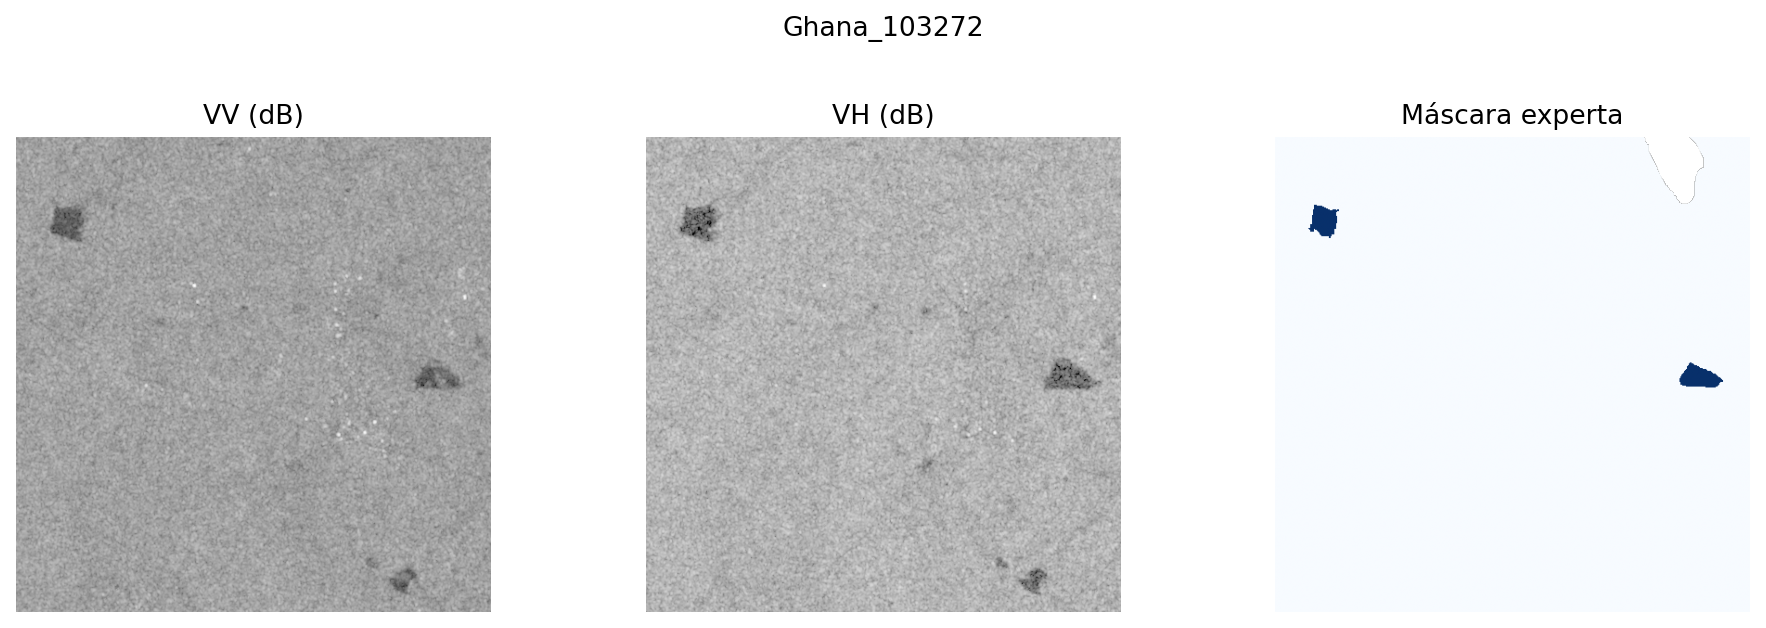

In [11]:
seed_everything(CONFIG['seed'])
model = UNet()
with torch.inference_mode():
    shape = tuple(model(torch.zeros(1,2,512,512)).shape)
print('Entrada: [1,2,512,512] | Salida:', shape)
print('Parámetros U-Net SAR:', f'{sum(p.numel() for p in model.parameters()):,}')
sample_record = records['train'][0]
raw, target, _ = read_sar(sample_record)
fig, axes = plt.subplots(1,3,figsize=(12,4))
for axis, array, title, cmap in zip(axes, [raw[0], raw[1], np.ma.masked_where(target<0,target)],
                                  ['VV (dB)', 'VH (dB)', 'Máscara experta'], ['gray','gray','Blues']):
    axis.imshow(array,cmap=cmap); axis.set_title(title); axis.axis('off')
fig.suptitle(sample_record['id'])
save_figure(fig, '01_datos.png')
del model


## 2. Ablación de supervisión y función de pérdida

Se compara el factorial **2 fuentes de supervisión × 3 pérdidas**. BCE opera sobre logits; Dice y BCE + Dice se calculan en precisión simple incluso al usar precisión mixta. Cada pérdida se promedia por chip sobre sus píxeles válidos. Un chip débil conserva peso 0,3 incluso si todos los chips de un lote son débiles.

En la GPU compatible se utiliza precisión mixta BF16 para evitar el desbordamiento observado con FP16; las pérdidas se reducen en FP32. La inicialización y el orden de datos se reinician con la semilla 42 en cada experimento. Se usa AdamW, recorte del gradiente a norma 1, hasta 50 épocas y parada temprana con paciencia 10 por **pérdida de validación**. No se consulta prueba ni Bolivia para elegir checkpoints o umbrales. Agregar datos débiles aumenta los pasos por época: el contraste mide el efecto conjunto de esos datos y del presupuesto adicional, no una comparación a igual número de actualizaciones.

**Cómo leer las curvas:** BCE, Dice y su suma tienen escalas diferentes. La comparación entre modelos se hace con IoU y F1, no con el valor absoluto de pérdidas diferentes. En `gold_weak`, la pérdida de entrenamiento está ponderada por 0,3 para los chips débiles, mientras la validación usa etiquetas doradas con peso 1. La separación entre ambas curvas no permite, por sí sola, concluir sobreajuste.


In [12]:
def segmentation_loss(logits, target, weights, kind='combined'):
    """Mask nodata, reduce within each chip and preserve weak-label weights."""
    logits, target = logits.float(), target.float()
    valid = (target == 0) | (target == 1)
    truth = target.clamp(0,1)
    axes = (1,2,3)
    support = valid.sum(dim=axes)
    bce = (F.binary_cross_entropy_with_logits(logits,truth,reduction='none')*valid).sum(dim=axes)/support.clamp_min(1)
    probability = logits.sigmoid()*valid
    dice = 1-(2*(probability*truth).sum(dim=axes)+1e-6)/(probability.sum(dim=axes)+(truth*valid).sum(dim=axes)+1e-6)
    losses = {'bce':bce, 'dice':dice, 'combined':bce+dice}[kind]
    return (losses*weights.float().reshape(-1)*(support>0)).sum()/(support>0).sum().clamp_min(1)


def binary_counts(target, probability):
    valid = np.isin(target,[0,1])
    if not np.isfinite(probability[valid]).all() or ((probability[valid]<0)|(probability[valid]>1)).any():
        raise ValueError('Invalid probabilities.')
    truth, prediction = target[valid].astype(bool), probability[valid]>=CONFIG['threshold']
    return dict(tp=int((truth&prediction).sum()), fp=int((~truth&prediction).sum()),
                fn=int((truth&~prediction).sum()), tn=int((~truth&~prediction).sum()))


def count_metrics(counts):
    tp,fp,fn,tn = [counts[key] for key in ['tp','fp','fn','tn']]
    def divide(x,y):
        return x/y if y else None
    return dict(**counts, valid_pixels=tp+fp+fn+tn, iou=divide(tp,tp+fp+fn),
                precision=divide(tp,tp+fp), recall=divide(tp,tp+fn), f1=divide(2*tp,2*tp+fp+fn),
                omission=divide(fn,tp+fn), commission=divide(fp,tp+fp))


In [13]:
def limited(entries, split):
    return entries[:(8 if split=='train' else 2)] if MODE=='smoke' else entries


def make_loader(dataset, shuffle=False):
    generator = torch.Generator().manual_seed(CONFIG['seed'])
    return DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=shuffle, num_workers=0,
                      pin_memory=DEVICE.type=='cuda', generator=generator)


def training_state():
    numpy_state = np.random.get_state()
    return dict(python=random.getstate(), numpy=[numpy_state[0],numpy_state[1].tolist(),*numpy_state[2:]],
                torch=torch.get_rng_state(), cuda=torch.cuda.get_rng_state_all() if DEVICE.type=='cuda' else [])


def restore_training_state(state):
    random.setstate(state['python'])
    n=state['numpy']; np.random.set_state((n[0],np.array(n[1],dtype='uint32'),n[2],n[3],n[4]))
    torch.set_rng_state(state['torch'])
    if state['cuda']:
        torch.cuda.set_rng_state_all(state['cuda'])


def save_checkpoint(path, state):
    temporary=path.with_suffix('.tmp')
    torch.save(state,temporary); temporary.replace(path)


In [14]:
def train_experiment(name, training, validation, channels, loss_name):
    """Train a new model, record actual budget, and select only with validation loss."""
    run_dir=RUN_DIR/'models'/name
    run_dir.mkdir(parents=True,exist_ok=False)
    experiment=dict(name=name, configuration=CONFIG, channels=channels, loss=loss_name,
        manifest=manifest['identity'], train_ids=[r['id'] for r in training.records],
        validation_ids=[r['id'] for r in validation.records],
        normalization=training.sar_stats, optical_normalization=training.optical_stats,
        clear_masks=signature({r['id']:hashlib.sha256(clear_masks[r['id']].tobytes()).hexdigest()
                              for r in training.records+validation.records}) if training.masks is not None else None)
    experiment_id=signature(experiment)
    seed_everything(CONFIG['seed'])
    model=UNet(channels,CONFIG['base_channels']).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=CONFIG['learning_rate'],weight_decay=CONFIG['weight_decay'])
    scaler=torch.amp.GradScaler('cuda',enabled=DEVICE.type=='cuda' and AMP_DTYPE==torch.float16,init_scale=1024)
    train_loader,val_loader=make_loader(training,True),make_loader(validation)
    start,best,stale,history=0,float('inf'),0,[]
    write_json(run_dir/'configuration.json',experiment)
    if DEVICE.type=='cuda':
        torch.cuda.reset_peak_memory_stats()
    started=time.monotonic()
    for epoch in range(start,CONFIG['epochs']):
        if stale>=CONFIG['patience']:
            break
        averages=[]
        for is_training,loader in [(True,train_loader),(False,val_loader)]:
            model.train(is_training)
            total,support=0.0,0
            for image,target,weights in loader:
                image,target,weights=[value.to(DEVICE,non_blocking=True) for value in [image,target,weights]]
                optimizer.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(is_training),torch.amp.autocast('cuda',enabled=DEVICE.type=='cuda',dtype=AMP_DTYPE):
                    loss=segmentation_loss(model(image),target,weights,loss_name)
                if not torch.isfinite(loss):
                    raise FloatingPointError(f'Nonfinite loss in {name}, epoch {epoch+1}')
                if is_training:
                    scaler.scale(loss).backward(); scaler.unscale_(optimizer)
                    norm=nn.utils.clip_grad_norm_(model.parameters(),1.0)
                    if not torch.isfinite(norm):
                        raise FloatingPointError(f'Nonfinite gradients in {name}')
                    scaler.step(optimizer); scaler.update()
                total+=loss.item()*len(image); support+=len(image)
            assert support>0
            averages.append(total/support)
        improved=averages[1]<best
        best=min(best,averages[1]); stale=0 if improved else stale+1
        history.append(dict(epoch=epoch+1,train_loss=averages[0],val_loss=averages[1]))
        elapsed=time.monotonic()-started
        state=dict(model=model.state_dict(),optimizer=optimizer.state_dict(),scaler=scaler.state_dict(),
            epoch=epoch+1,best=best,stale=stale,history=history,signature=experiment_id,
            elapsed_seconds=elapsed,rng=training_state(),train_generator=train_loader.generator.get_state(),
            val_generator=val_loader.generator.get_state())
        save_checkpoint(run_dir/'last.pt',state)
        if improved:
            save_checkpoint(run_dir/'best.pt',state)
        pd.DataFrame(history).to_csv(run_dir/'history.csv',index=False)
        write_json(RUN_DIR/'progress.json',dict(experiment=name,epoch=epoch+1,train_loss=averages[0],
                   val_loss=averages[1],elapsed_seconds=elapsed,status='training'))
        if epoch==0 or (epoch+1)%5==0:
            print(f'{name}: época {epoch+1}, pérdida validación {averages[1]:.5f}',flush=True)
    elapsed=time.monotonic()-started
    result=dict(name=name,signature=experiment_id,channels=channels,loss=loss_name,
        train_chips=len(training),validation_chips=len(validation),epochs=len(history),
        best_epoch=int(min(history,key=lambda r:r['val_loss'])['epoch']),best_validation_loss=best,
        steps_per_epoch=len(train_loader),total_steps=len(train_loader)*len(history),training_seconds=elapsed,
        parameters=sum(p.numel() for p in model.parameters()),scientific_run=MODE=='full',
        initialized_from_scratch=True, previous_checkpoints_loaded=0,
        peak_cuda_bytes=torch.cuda.max_memory_allocated() if DEVICE.type=='cuda' else 0)
    write_json(run_dir/'complete.json',result)
    del model,optimizer,scaler,train_loader,val_loader,state
    gc.collect()
    if DEVICE.type=='cuda':
        torch.cuda.empty_cache()
    return result


In [15]:
test_results=[]
def check(name, condition):
    assert bool(condition), f'Failed acceptance check: {name}'
    test_results.append(dict(prueba=name,estado='OK'))

for channels in [2,15]:
    test_model=UNet(channels,8).eval()
    with torch.inference_mode():
        check(f'U-Net {channels} canales conserva dimensiones impares',
              tuple(test_model(torch.zeros(1,channels,33,35)).shape)==(1,1,33,35))
del test_model
for kind in ['bce','dice','combined']:
    logits=torch.zeros(1,1,2,2,requires_grad=True)
    target_test=torch.tensor([[[[1.,-1.],[0.,-1.]]]])
    loss=segmentation_loss(logits,target_test,torch.ones(1),kind)
    loss.backward()
    check(f'{kind}: pérdida y gradientes finitos',torch.isfinite(loss)&torch.isfinite(logits.grad).all())
    check(f'{kind}: nodata sin gradiente',torch.equal(logits.grad[target_test==-1],torch.zeros(2)))
    strong=segmentation_loss(logits.detach(),target_test,torch.ones(1),kind)
    weak=segmentation_loss(logits.detach(),target_test,torch.tensor([0.3]),kind)
    check(f'{kind}: peso débil en lote exclusivamente débil',torch.isclose(weak,strong*0.3))
    empty_logits=torch.zeros(1,1,2,2,requires_grad=True)
    empty=segmentation_loss(empty_logits,torch.full_like(empty_logits,-1),torch.ones(1),kind)
    empty.backward()
    check(f'{kind}: lote sin datos produce cero',empty.item()==0 and empty_logits.grad.abs().sum()==0)
counts=binary_counts(np.array([1,0,1,0,-1]),np.array([1.,1.,0.,0.,1.]))
check('Matriz de confusión con resultado conocido',counts==dict(tp=1,fp=1,fn=1,tn=1))
check('IoU, F1, precisión y recall conocidos',count_metrics(counts)['iou']==1/3 and count_metrics(counts)['f1']==0.5)
check('Unión vacía queda indefinida',count_metrics(dict(tp=0,fp=0,fn=0,tn=4))['iou'] is None)
for left,right in product(SPLIT_FILES,repeat=2):
    if left<right:
        check(f'Particiones {left}/{right} disjuntas',not({r['id'] for r in records[left]}&{r['id'] for r in records[right]}))
gold_ids={r['id'] for split in SPLIT_FILES for r in records[split]}
check('Débiles sin Bolivia ni coincidencias doradas',all(r['country']!='Bolivia' and r['id'] not in gold_ids for r in records['weak']))
check('Normalización ajustada solo con train',set(sar_normalization['training_ids'])=={r['id'] for r in records['train']})
toy_target=np.zeros((32,32),dtype='int8');toy_target[3:12,5:15]=1;toy_target[:2]=-1
toy_image=np.stack([np.maximum(toy_target,0),np.maximum(toy_target,0)]).astype('float32')
SAR_CACHE['augmentation_fixture']=(toy_image,toy_target,{})
toy=FloodDataset([dict(id='augmentation_fixture',weight=1.)],dict(mean=[0,0],std=[1,1]),augment=True)
for repeat in range(4):
    image_t,target_t,_=toy[0]
    check(f'Aumentos sincronizan imagen y máscara ({repeat+1})',
          torch.equal(image_t[0][target_t[0]>=0],target_t[0][target_t[0]>=0]))
del SAR_CACHE['augmentation_fixture']
from rasterio.io import MemoryFile
from rasterio.transform import from_origin
profile=dict(driver='GTiff',width=2,height=2,count=1,dtype='float32',crs='EPSG:4326',transform=from_origin(0,2,1,1))
with MemoryFile() as a, MemoryFile() as b:
    with a.open(**profile) as left, b.open(**profile) as right:
        check('Alineación geográfica positiva',aligned(left,right))
        right.transform=from_origin(0,3,1,1)
        check('Desalineación geográfica detectada',not aligned(left,right))
if fusion_block is None:
    r=clear_records['train'][0]
    a=FloodDataset([r],matched_sar_normalization,masks=clear_masks)[0]
    b=FloodDataset([r],matched_sar_normalization,optical_normalization,clear_masks)[0]
    check('Fusión usa exactamente la misma máscara que SAR',torch.equal(a[1],b[1]))
    check('Fusión tiene quince canales',b[0].shape[0]==15)
    check('Fusión conserva los dos canales SAR',torch.equal(a[0],b[0][:2]))
seed_everything(42)
small=UNet(2,8).eval()
test_path=RUN_DIR/'tests/roundtrip.pt'; test_path.parent.mkdir(exist_ok=True)
torch.save(small.state_dict(),test_path)
restored=UNet(2,8).eval(); restored.load_state_dict(torch.load(test_path,weights_only=True))
with torch.inference_mode():
    z=torch.randn(1,2,32,32)
    check('Checkpoint restaura exactamente la predicción',torch.equal(small(z),restored(z)))
del small,restored,a,b
if DEVICE.type=='cuda':
    for channels in [2,15] if fusion_block is None else [2]:
        sample=records['train'][0] if channels==2 else clear_records['train'][0]
        dataset=FloodDataset([sample],sar_normalization if channels==2 else matched_sar_normalization,
            optical_normalization if channels==15 else None,clear_masks if channels==15 else None)
        gpu_image,gpu_target,gpu_weights=next(iter(make_loader(dataset)))
        gpu_image,gpu_target,gpu_weights=[x.to(DEVICE) for x in [gpu_image,gpu_target,gpu_weights]]
        gpu_model=UNet(channels,32).to(DEVICE)
        gpu_optimizer=torch.optim.AdamW(gpu_model.parameters())
        gpu_scaler=torch.amp.GradScaler('cuda',enabled=AMP_DTYPE==torch.float16,init_scale=1024)
        with torch.amp.autocast('cuda',dtype=AMP_DTYPE):
            gpu_output=gpu_model(gpu_image)
            gpu_loss=segmentation_loss(gpu_output,gpu_target,gpu_weights,'combined')
        gpu_scaler.scale(gpu_loss).backward();gpu_scaler.unscale_(gpu_optimizer)
        gpu_norm=nn.utils.clip_grad_norm_(gpu_model.parameters(),1.)
        check(f'GPU {channels} canales: salida nativa 512×512',tuple(gpu_output.shape)==(1,1,512,512))
        check(f'GPU {channels} canales: pérdida y gradientes finitos con AMP',torch.isfinite(gpu_loss)&torch.isfinite(gpu_norm))
        del gpu_model,gpu_optimizer,gpu_scaler,gpu_loss,gpu_output,gpu_image,gpu_target,gpu_weights
        torch.cuda.empty_cache()
write_json(RUN_DIR/'tests/acceptance.json',test_results)
display(pd.DataFrame(test_results))

check('Ejecución independiente sin reanudación', MODE in {'full','smoke'} and os.environ.get('FLOOD_RESUME','0')=='0')
check('Originales ópticos locales disponibles', len(optical_objects)==sum(manifest['original_counts'][split] for split in SPLIT_FILES))
cloud_audit=read_json(RUN_DIR/'optical_protocol.json')
check('Todas las máscaras de nubes calculadas en esta ejecución', cloud_audit['computed_masks']==sum(len(records[split]) for split in SPLIT_FILES) and cloud_audit['cache_hits']==0)
check('Caché confinada a la ejecución actual', (RUN_DIR/'cache/cloud-masks').resolve().is_relative_to(RUN_DIR.resolve()))
check('Normalización SAR emparejada usa solo train', fusion_block is not None or set(matched_sar_normalization['training_ids'])=={r['id'] for r in clear_records['train']})
check('Normalización óptica usa solo train', fusion_block is not None or set(optical_normalization['training_ids'])=={r['id'] for r in clear_records['train']})
write_json(RUN_DIR/'tests/acceptance.json',test_results)
display(pd.DataFrame(test_results[-6:]))


,prueba,estado
0,U-Net 2 canales conserva dimensiones impares,OK
1,U-Net 15 canales conserva dimensiones impares,OK
2,bce: pérdida y gradientes finitos,OK
3,bce: nodata sin gradiente,OK
4,bce: peso débil en lote exclusivamente débil,OK
5,bce: lote sin datos produce cero,OK
6,dice: pérdida y gradientes finitos,OK
7,dice: nodata sin gradiente,OK
8,dice: peso débil en lote exclusivamente débil,OK
9,dice: lote sin datos produce cero,OK


,prueba,estado
0,Ejecución independiente sin reanudación,OK
1,Originales ópticos locales disponibles,OK
2,Todas las máscaras de nubes calculadas en esta...,OK
3,Caché confinada a la ejecución actual,OK
4,Normalización SAR emparejada usa solo train,OK
5,Normalización óptica usa solo train,OK


gold_bce: época 1, pérdida validación 0.29084


gold_bce: época 5, pérdida validación 0.18675


gold_bce: época 10, pérdida validación 0.16529


gold_bce: época 15, pérdida validación 0.15619


gold_bce: época 20, pérdida validación 0.15890


...

gold_weak_combined: época 5, pérdida validación 0.82421


gold_weak_combined: época 10, pérdida validación 0.82194


gold_weak_combined: época 15, pérdida validación 0.77942


gold_weak_combined: época 20, pérdida validación 0.80938


,name,train_chips,epochs,best_epoch,best_validation_loss,total_steps,training_seconds
0,gold_bce,251,50,47,0.123844,3150,232.449331
1,gold_dice,251,34,24,0.486784,2142,162.559581
2,gold_combined,251,50,46,0.662165,3150,234.023458
3,gold_weak_bce,4401,35,25,0.148076,38535,2044.867301
4,gold_weak_dice,4401,11,1,0.575078,12111,647.279459
5,gold_weak_combined,4401,22,12,0.774748,24222,1265.718272


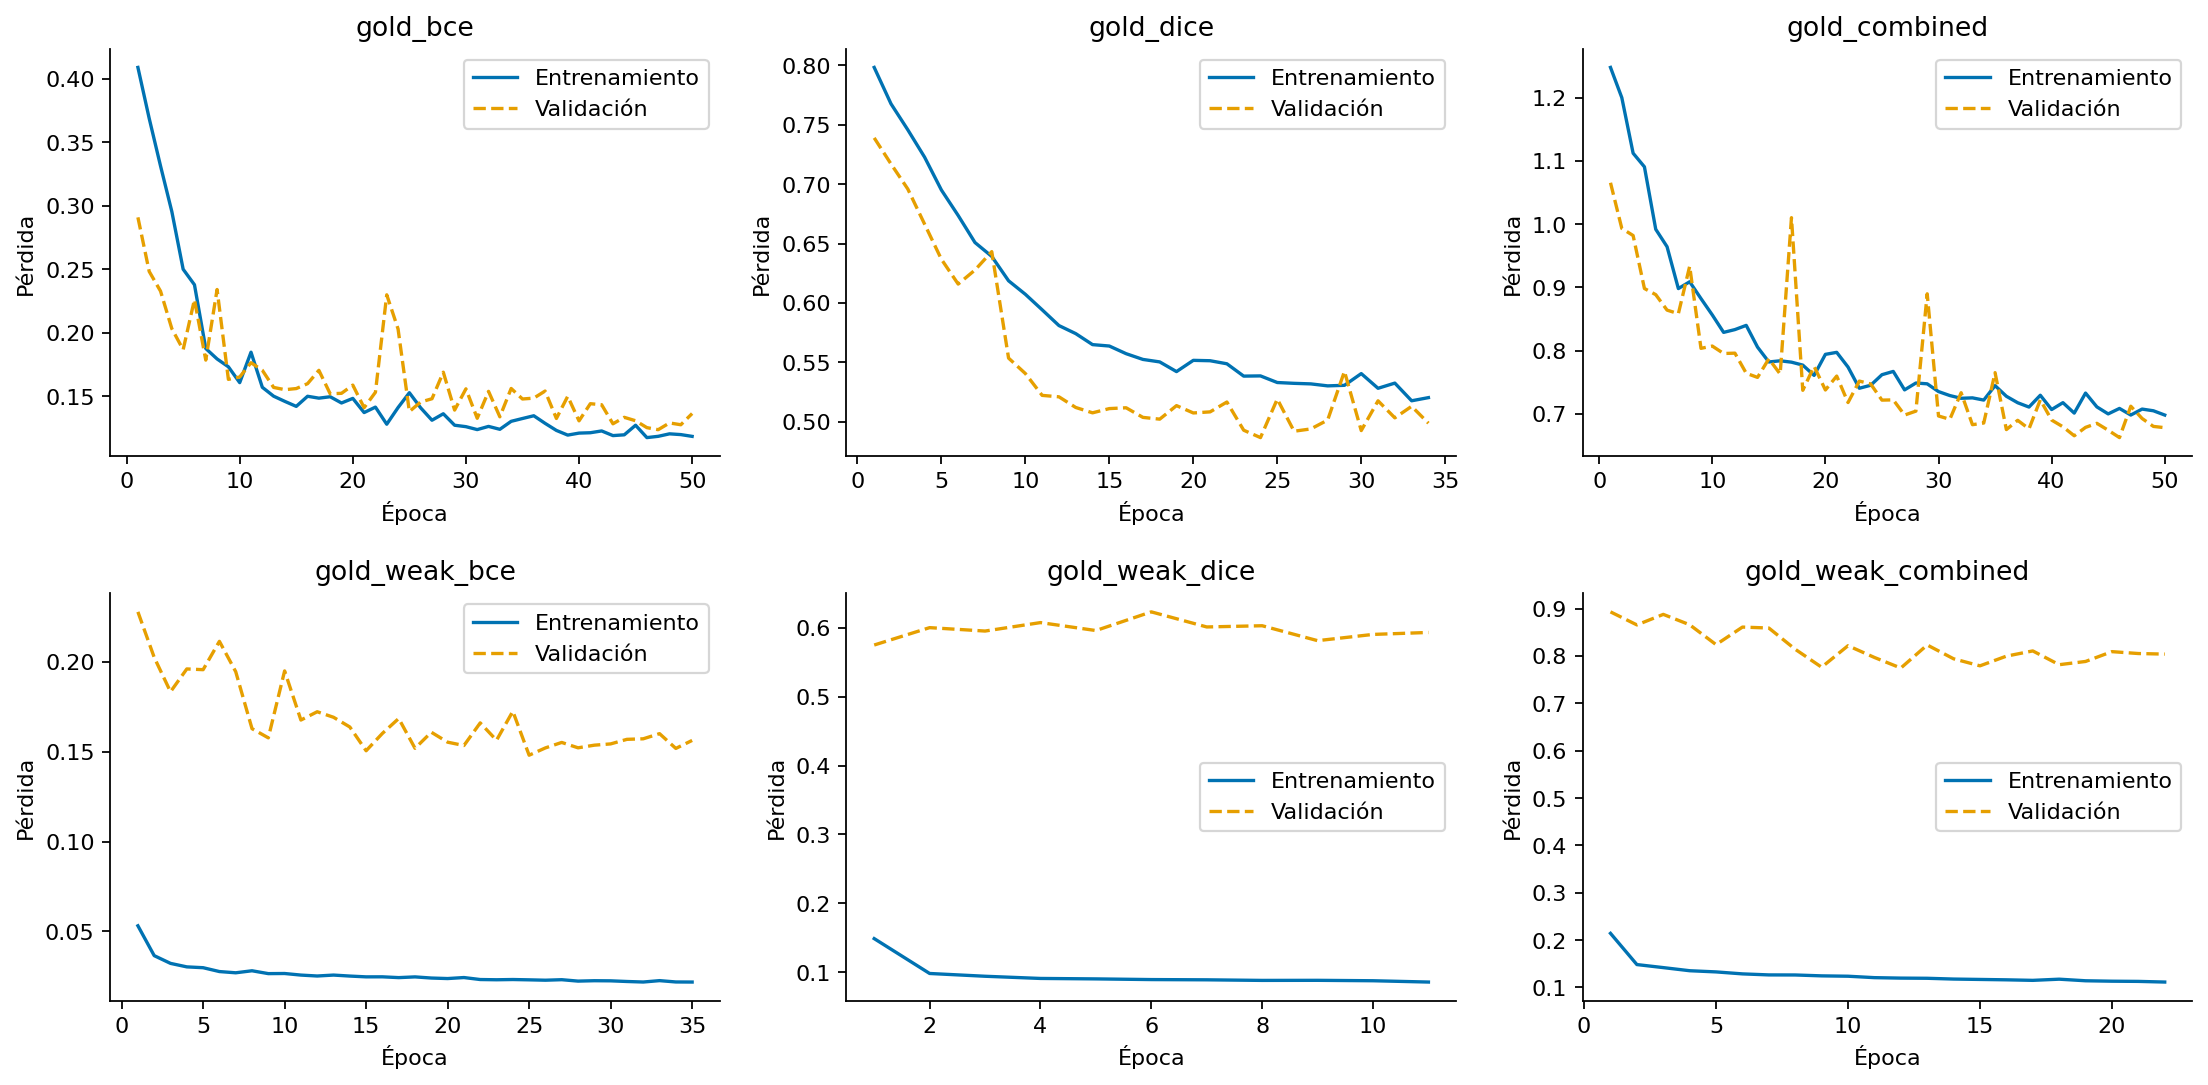

In [16]:
sar_training_results=[]
for supervision,loss_name in product(['gold','gold_weak'],['bce','dice','combined']):
    train_entries=limited(records['train'],'train')
    if supervision=='gold_weak':
        train_entries=train_entries+limited(records['weak'],'train')
    training=FloodDataset(train_entries,sar_normalization,augment=True)
    validation=FloodDataset(limited(records['val'],'val'),sar_normalization)
    sar_training_results.append(train_experiment(f'{supervision}_{loss_name}',training,validation,2,loss_name))
training_table=pd.DataFrame(sar_training_results)
training_table.to_csv(RUN_DIR/'sar_training.csv',index=False)
display(training_table[['name','train_chips','epochs','best_epoch','best_validation_loss','total_steps','training_seconds']])
fig,axes=plt.subplots(2,3,figsize=(14,7))
for axis,result in zip(axes.flat,sar_training_results):
    history=pd.read_csv(RUN_DIR/'models'/result['name']/'history.csv')
    axis.plot(history.epoch,history.train_loss,label='Entrenamiento',color=COLORS[0])
    axis.plot(history.epoch,history.val_loss,'--',label='Validación',color=COLORS[1])
    axis.set(title=result['name'],xlabel='Época',ylabel='Pérdida'); axis.legend()
save_figure(fig,'02_curvas_ablacion.png')


## 3. Evaluación en distribución

Se evalúa en los chips expertos de la partición oficial `test`, distintos de los usados para entrenar y validar. Se guardan mapas de probabilidad GeoTIFF con la misma geometría de entrada. Las métricas se vuelven a calcular **leyendo esos archivos**, para comprobar que la evidencia persistida reproduce los resultados mostrados.

Se informa IoU promedio por chip sobre uniones definidas y, por separado, el promedio con suavizado `epsilon=1e-7` que asigna 1 a una unión vacía. También se calculan métricas agrupando todos los píxeles válidos. Son agregaciones distintas; los conteos y el soporte acompañan cada resultado. Un cociente sin denominador se informa como indefinido, nunca como un resultado perfecto.


,experiment,split,mean_chip_iou,reference_mean_chip_iou,iou,f1,precision,recall,omission,commission,chips,valid_pixels
0,gold_bce,test,0.3940,0.4078,0.6592,0.7946,0.8582,0.7398,0.2602,0.1418,88,20443959
1,gold_dice,test,0.3947,0.3947,0.6188,0.7645,0.7117,0.8258,0.1742,0.2883,88,20443959
2,gold_combined,test,0.4055,0.4055,0.6454,0.7845,0.7750,0.7941,0.2059,0.2250,88,20443959
3,gold_weak_bce,test,0.3324,0.3551,0.6122,0.7595,0.7978,0.7247,0.2753,0.2022,88,20443959
4,gold_weak_dice,test,0.3470,0.3545,0.5937,0.7450,0.7323,0.7583,0.2417,0.2677,88,20443959
5,gold_weak_combined,test,0.3582,0.3801,0.6147,0.7614,0.7495,0.7736,0.2264,0.2505,88,20443959


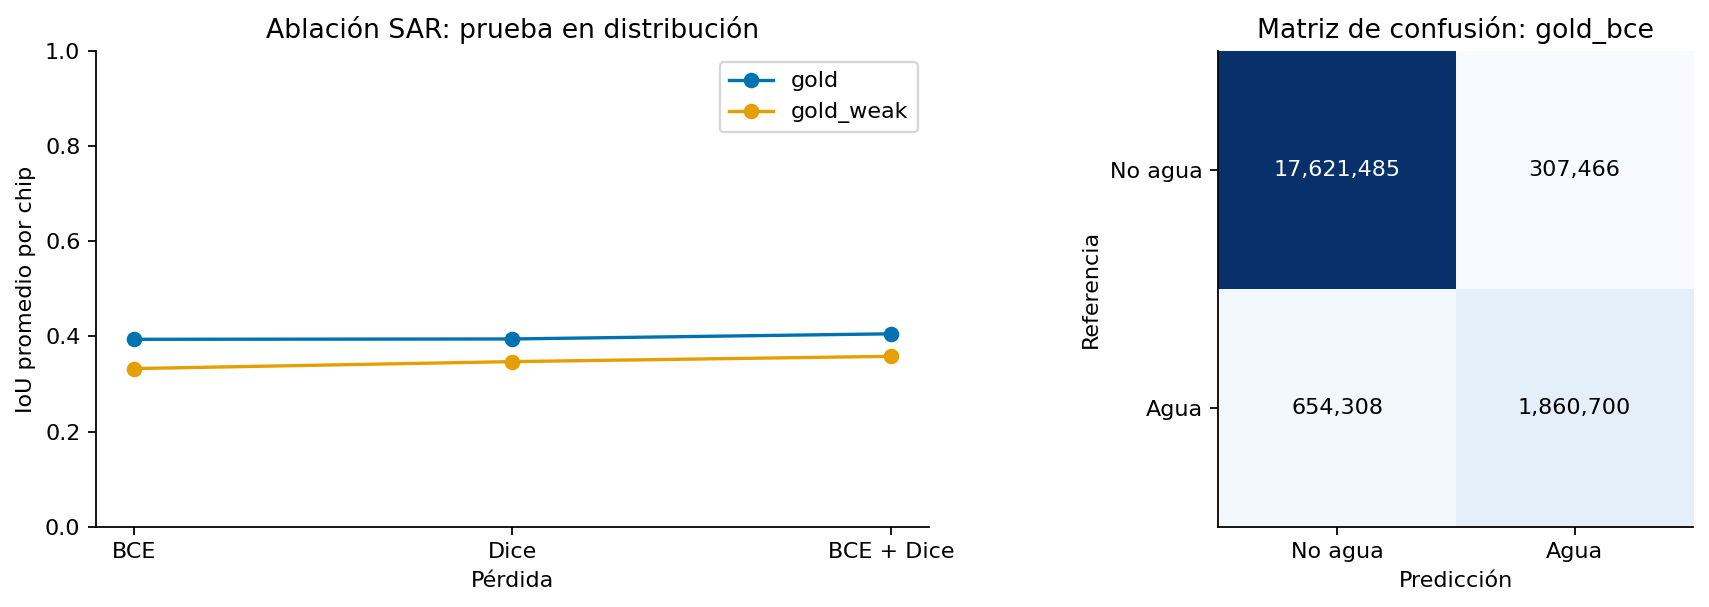

La referencia predefinida **gold_bce** produjo 307,466 falsos positivos y 654,308 falsos negativos. Los primeros sobreestiman agua; los segundos omiten agua anotada. El predominio de no agua puede favorecer una accuracy alta sin asegurar una buena segmentación; por eso se reportan métricas de agua.

In [17]:
def load_model(name, channels):
    model=UNet(channels,CONFIG['base_channels'])
    state=torch.load(RUN_DIR/'models'/name/'best.pt',map_location='cpu',weights_only=True)
    model.load_state_dict(state['model'])
    return model.to(DEVICE).eval()


def aggregate_rows(rows):
    totals={key:sum(row[key] for row in rows) for key in ['tp','fp','fn','tn']}
    defined=[row['iou'] for row in rows if row['iou'] is not None]
    reference=[(row['tp']+1e-7)/(row['tp']+row['fp']+row['fn']+1e-7) for row in rows]
    return dict(pooled=count_metrics(totals),mean_chip_iou=float(np.mean(defined)) if defined else None,
                reference_mean_chip_iou=float(np.mean(reference)) if rows else None,
                chips=len(rows),defined_iou_chips=len(defined),empty_union_chips=len(rows)-len(defined),
                threshold=CONFIG['threshold'])


def evaluate_experiment(name, dataset, channels, split):
    """Export probabilities then independently recompute metrics from those rasters."""
    model=load_model(name,channels)
    destination=RUN_DIR/'predictions'/name/split
    destination.mkdir(parents=True,exist_ok=True)
    rows=[]
    with torch.inference_mode():
        for index,record in enumerate(dataset.records):
            image,target,_=dataset[index]
            probability=model(image[None].to(DEVICE)).sigmoid()[0,0].cpu().numpy()
            target=target[0].numpy()
            before=binary_counts(target,probability)
            _,_,profile=read_sar(record)
            profile.update(count=1,dtype='float32',nodata=-1,compress='deflate')
            probability[target<0]=-1
            path=destination/f'{record["id"]}_probability.tif'
            with rasterio.open(path,'w',**profile) as output:
                output.write(probability.astype('float32'),1)
            with rasterio.open(path) as saved,rasterio.open(record['image']) as source:
                assert aligned(saved,source)
                probability=saved.read(1)
            assert np.all(probability[target<0]==-1)
            after=binary_counts(target,probability)
            assert before==after, 'Persisted predictions changed the confusion counts.'
            rows.append(dict(id=record['id'],country=record['country'],**count_metrics(after)))
    metrics=aggregate_rows(rows)
    pd.DataFrame(rows).to_csv(destination/'per_chip.csv',index=False)
    write_json(destination/'metrics.json',metrics)
    del model
    if DEVICE.type=='cuda':
        torch.cuda.empty_cache()
    return dict(experiment=name,split=split,mean_chip_iou=metrics['mean_chip_iou'],
                reference_mean_chip_iou=metrics['reference_mean_chip_iou'],
                **{key:metrics['pooled'][key] for key in ['iou','f1','precision','recall','omission','commission']},
                chips=metrics['chips'],valid_pixels=metrics['pooled']['valid_pixels'])


test_results_sar=[]
for result in sar_training_results:
    test_results_sar.append(evaluate_experiment(result['name'],
        FloodDataset(limited(records['test'],'test'),sar_normalization),2,'test'))
test_table=pd.DataFrame(test_results_sar)
test_table.to_csv(RUN_DIR/'sar_test_metrics.csv',index=False)
display(test_table.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for supervision,color in [('gold',COLORS[0]),('gold_weak',COLORS[1])]:
    names=[f'{supervision}_{loss}' for loss in ['bce','dice','combined']]
    values=test_table.set_index('experiment').loc[names]
    axes[0].plot(['BCE','Dice','BCE + Dice'],values.mean_chip_iou,'o-',label=supervision,color=color)
axes[0].set(xlabel='Pérdida',ylabel='IoU promedio por chip',ylim=(0,1),title='Ablación SAR: prueba en distribución')
axes[0].legend()
baseline_metrics=read_json(RUN_DIR/'predictions/gold_bce/test/metrics.json')['pooled']
matrix=np.array([[baseline_metrics['tn'],baseline_metrics['fp']],[baseline_metrics['fn'],baseline_metrics['tp']]])
axes[1].imshow(matrix,cmap='Blues')
for (row,column),value in np.ndenumerate(matrix):
    axes[1].text(column,row,f'{value:,}',ha='center',va='center',color='white' if value>matrix.max()/2 else 'black')
axes[1].set(xticks=[0,1],yticks=[0,1],xticklabels=['No agua','Agua'],yticklabels=['No agua','Agua'],
            xlabel='Predicción',ylabel='Referencia',title='Matriz de confusión: gold_bce')
save_figure(fig,'03_ablacion_y_confusion.png')
display(Markdown(f"La referencia predefinida **gold_bce** produjo {baseline_metrics['fp']:,} falsos positivos y "
    f"{baseline_metrics['fn']:,} falsos negativos. Los primeros sobreestiman agua; los segundos omiten agua anotada. "
    "El predominio de no agua puede favorecer una accuracy alta sin asegurar una buena segmentación; por eso se reportan métricas de agua."))


## 4. Generalización geográfica: Bolivia

Los quince chips dorados oficiales de Bolivia quedan fuera del entrenamiento, normalización y selección de checkpoints. Se usa el mismo umbral 0,5. La brecha se define como **IoU de prueba en distribución menos IoU de Bolivia**: puede ser positiva, cero o negativa. Una región nueva no tiene necesariamente peor rendimiento.


,experiment,iou_distribucion,iou_bolivia,brecha
0,gold_bce,0.3940,0.4456,-0.0516
1,gold_dice,0.3947,0.4601,-0.0654
2,gold_combined,0.4055,0.4676,-0.0621
3,gold_weak_bce,0.3324,0.3433,-0.0109
4,gold_weak_dice,0.3470,0.4758,-0.1288
5,gold_weak_combined,0.3582,0.4416,-0.0834


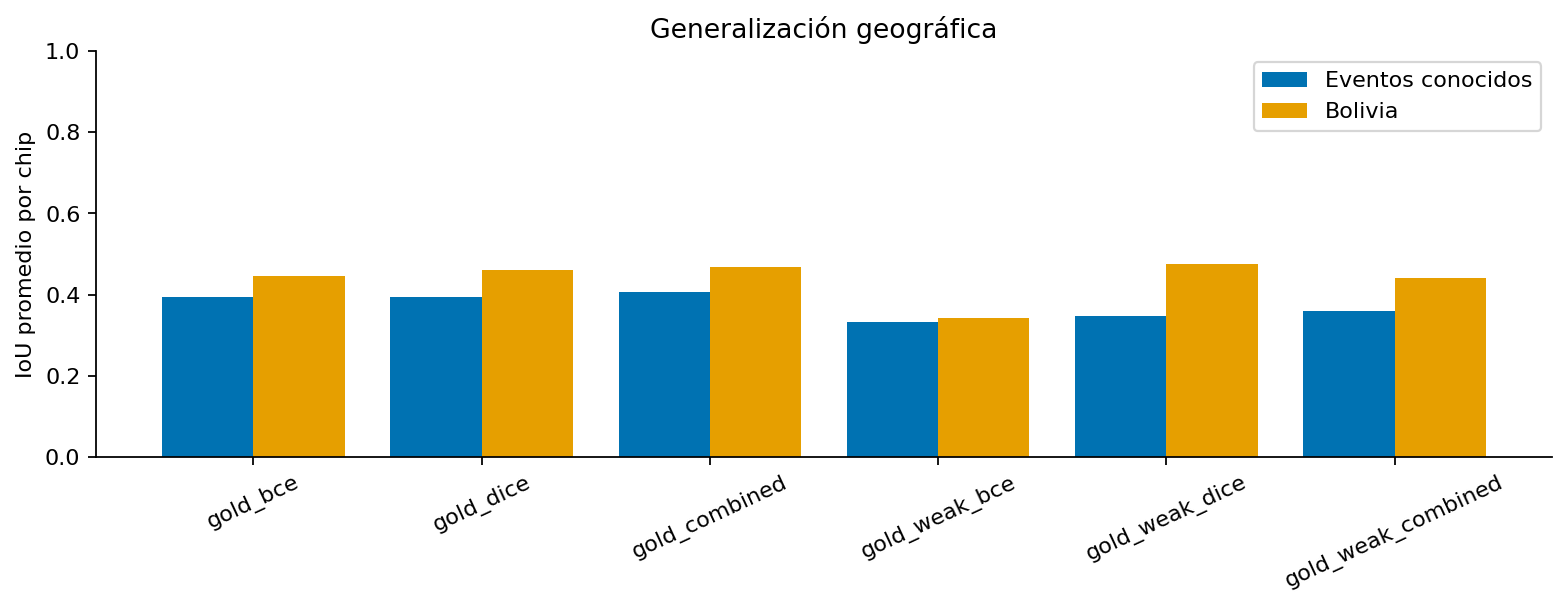

**Hipótesis 1 — cobertura y dificultad del evento.** La proporción de agua abierta, vegetación inundada, superficies lisas y zonas urbanas puede cambiar la respuesta SAR y la dificultad de segmentación. Una Bolivia más homogénea también podría obtener mayor IoU.

**Hipótesis 2 — adquisición y distribución radiométrica.** Diferencias de órbita, ángulo de incidencia, relieve o fecha pueden desplazar VV/VH frente al entrenamiento. Este ensayo no aísla esos factores ni demuestra causalidad.

**Límite:** los chips pertenecen a un mismo evento y no son observaciones geográficas independientes. Una única semilla y un solo país reservado no demuestran generalización universal.

In [18]:
bolivia_results=[]
for result in sar_training_results:
    bolivia_results.append(evaluate_experiment(result['name'],
        FloodDataset(limited(records['bolivia'],'bolivia'),sar_normalization),2,'bolivia'))
bolivia_table=pd.DataFrame(bolivia_results)
geographic=test_table[['experiment','mean_chip_iou']].rename(columns={'mean_chip_iou':'iou_distribucion'}).merge(
    bolivia_table[['experiment','mean_chip_iou']].rename(columns={'mean_chip_iou':'iou_bolivia'}),on='experiment',validate='one_to_one')
geographic['brecha']=geographic.iou_distribucion-geographic.iou_bolivia
geographic.to_csv(RUN_DIR/'geographic_gap.csv',index=False)
display(geographic.round(4))
fig,axis=plt.subplots(figsize=(10,4))
x=np.arange(len(geographic))
axis.bar(x-0.2,geographic.iou_distribucion,0.4,label='Eventos conocidos',color=COLORS[0])
axis.bar(x+0.2,geographic.iou_bolivia,0.4,label='Bolivia',color=COLORS[1])
axis.set(xticks=x,xticklabels=geographic.experiment,ylabel='IoU promedio por chip',ylim=(0,1),title='Generalización geográfica')
axis.tick_params(axis='x',labelrotation=25);axis.legend()
save_figure(fig,'04_brecha_geografica.png')
display(Markdown('**Hipótesis 1 — cobertura y dificultad del evento.** La proporción de agua abierta, vegetación inundada, '
    'superficies lisas y zonas urbanas puede cambiar la respuesta SAR y la dificultad de segmentación. Una Bolivia más homogénea '
    'también podría obtener mayor IoU.\n\n**Hipótesis 2 — adquisición y distribución radiométrica.** Diferencias de órbita, '
    'ángulo de incidencia, relieve o fecha pueden desplazar VV/VH frente al entrenamiento. Este ensayo no aísla esos factores '
    'ni demuestra causalidad.\n\n**Límite:** los chips pertenecen a un mismo evento y no son observaciones geográficas '
    'independientes. Una única semilla y un solo país reservado no demuestran generalización universal.'))


## 5. Análisis cualitativo de errores característicos del SAR

Se utiliza la referencia **gold_bce**, elegida antes de observar la prueba. Se buscan tres patrones observables: falsos positivos con señal baja, omisiones de agua con señal elevada y errores cerca del borde del agua. Los ejemplos se seleccionan por conteos, se muestran completos y se acompañan con su soporte. Una sombra de radar, el doble rebote o el suelo húmedo son **hipótesis físicas**, no etiquetas que pueda demostrar automáticamente una red a partir de VV/VH.


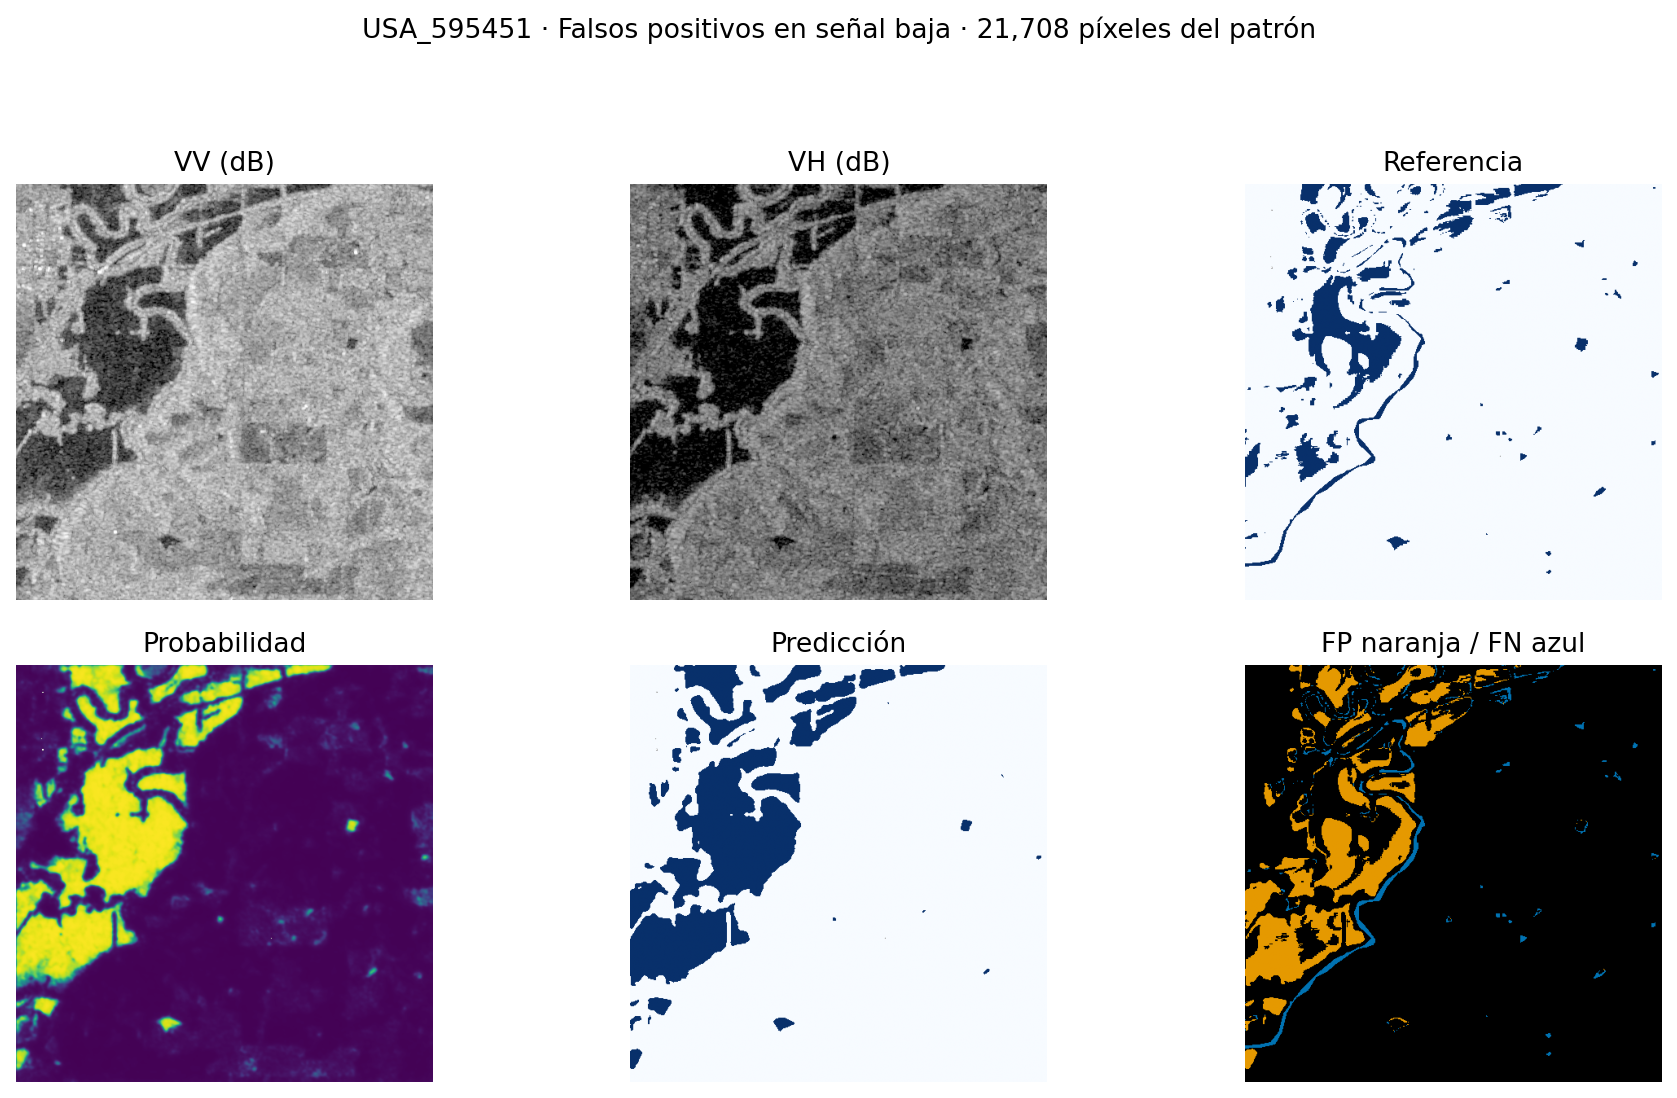

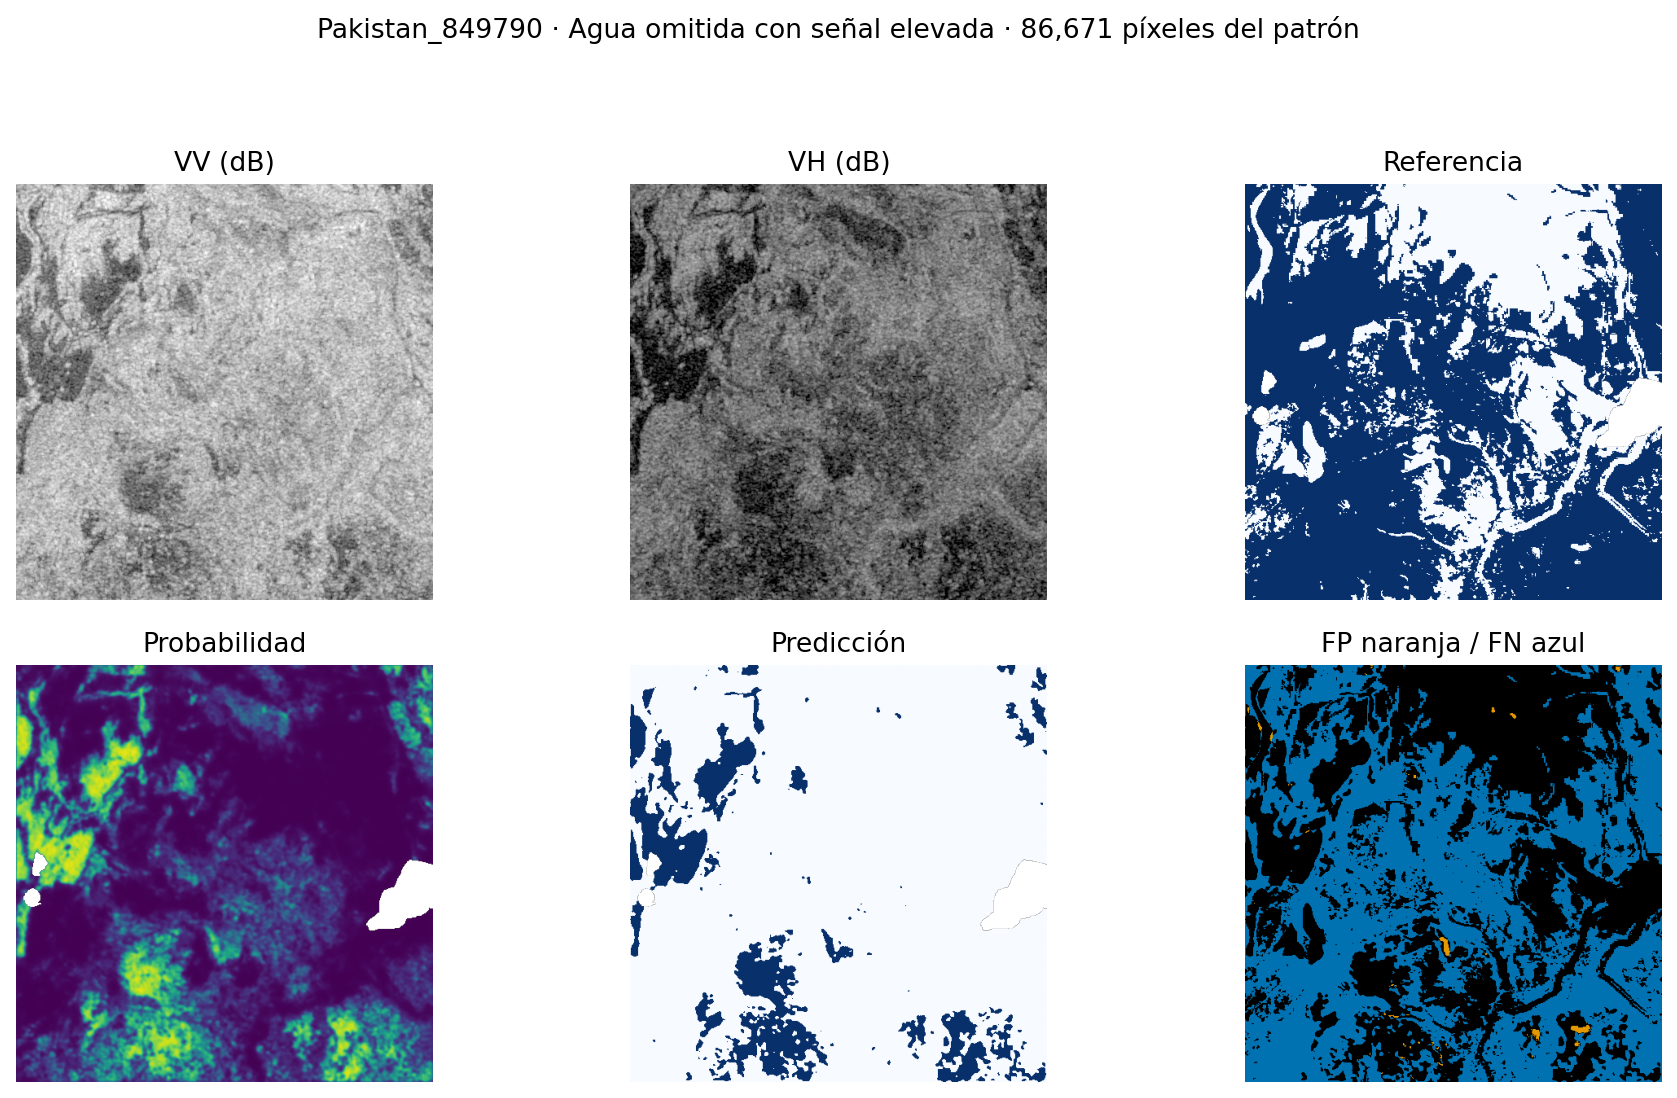

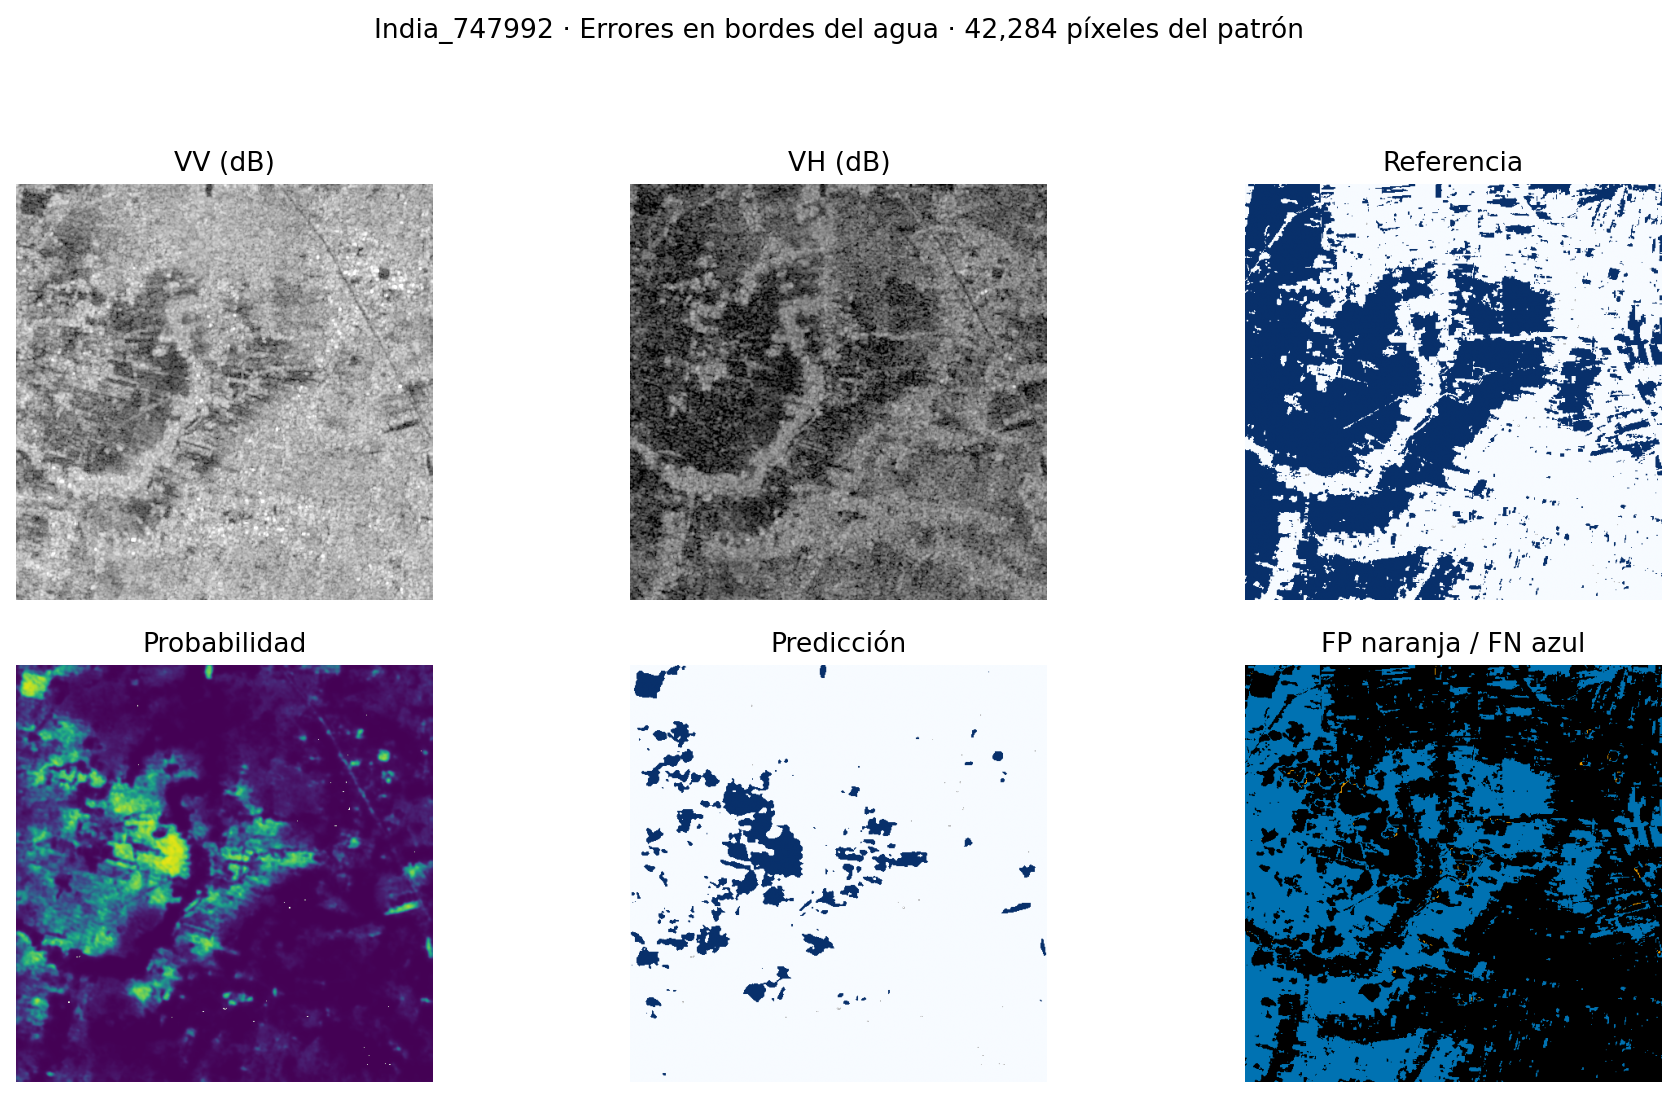

,id,pattern,pattern_pixels,fp,fn
0,USA_595451,Falsos positivos en señal baja,21708,25912,4248
1,Pakistan_849790,Agua omitida con señal elevada,86671,750,140086
2,India_747992,Errores en bordes del agua,42284,269,96519


**Señal baja:** los falsos positivos pueden corresponder a superficies lisas no acuáticas, zonas de sombra o suelo húmedo. El mapa confirma la confusión con la referencia, pero no identifica por sí mismo la cobertura o la geometría de iluminación.

**Señal elevada:** algunas omisiones son compatibles con agua en vegetación o estructuras que incrementan el retorno; el doble rebote urbano es una hipótesis que necesitaría evidencia adicional de edificaciones y geometría.

**Bordes:** mezcla de coberturas, resolución de 10 m, speckle y pequeñas diferencias de delineación pueden desplazar el contorno. El conteo usa una franja morfológica de tres píxeles, no una medición causal. La máscara experta también puede contener incertidumbre.

In [19]:
qualitative_candidates=[]
test_entries=limited(records['test'],'test')
for record in test_entries:
    raw,target,_=read_sar(record)
    with rasterio.open(RUN_DIR/'predictions/gold_bce/test'/f'{record["id"]}_probability.tif') as source:
        probability=source.read(1)
    prediction=probability>=CONFIG['threshold']; valid=target>=0
    fp=valid&(target==0)&prediction; fn=valid&(target==1)&~prediction
    boundary=(binary_dilation(target==1,iterations=3)^binary_erosion(target==1,iterations=3))&valid
    qualitative_candidates.append(dict(id=record['id'],
        low_backscatter_fp=int((fp&(raw[0]<-17)).sum()),
        high_backscatter_fn=int((fn&(raw[0]>-10)).sum()),
        boundary_error=int(((fp|fn)&boundary).sum()),fp=int(fp.sum()),fn=int(fn.sum())))
selected,used=[],set()
patterns=[('low_backscatter_fp','Falsos positivos en señal baja'),
          ('high_backscatter_fn','Agua omitida con señal elevada'),
          ('boundary_error','Errores en bordes del agua')]
for key,label in patterns:
    candidates=[r for r in qualitative_candidates if r['id'] not in used]
    if not candidates:
        candidates=qualitative_candidates
    chosen=max(candidates,key=lambda r:r[key]); used.add(chosen['id'])
    selected.append(dict(**chosen,pattern=label,pattern_pixels=chosen[key]))
    record=next(r for r in test_entries if r['id']==chosen['id'])
    raw,target,_=read_sar(record)
    with rasterio.open(RUN_DIR/'predictions/gold_bce/test'/f'{record["id"]}_probability.tif') as source:
        probability=source.read(1)
    valid=target>=0; prediction=probability>=0.5
    errors=np.zeros((*target.shape,3));errors[valid&(target==0)&prediction]=(0.9,0.6,0)
    errors[valid&(target==1)&~prediction]=(0,0.45,0.7)
    fig,axes=plt.subplots(2,3,figsize=(12,7))
    for axis,array,title,cmap in zip(axes.flat,
        [raw[0],raw[1],np.ma.masked_where(~valid,target),np.ma.masked_where(~valid,probability),
         np.ma.masked_where(~valid,prediction),errors],
        ['VV (dB)','VH (dB)','Referencia','Probabilidad','Predicción','FP naranja / FN azul'],
        ['gray','gray','Blues','viridis','Blues',None]):
        limits=dict(vmin=-30,vmax=0) if title.endswith('(dB)') else (dict(vmin=0,vmax=1) if cmap else {})
        axis.imshow(array,cmap=cmap,**limits);axis.set_title(title);axis.axis('off')
    fig.suptitle(f'{record["id"]} · {label} · {chosen[key]:,} píxeles del patrón')
    save_figure(fig,f'05_{key}.png')
qualitative_table=pd.DataFrame(selected)
qualitative_table.to_csv(RUN_DIR/'qualitative_cases.csv',index=False)
display(qualitative_table[['id','pattern','pattern_pixels','fp','fn']])
display(Markdown('**Señal baja:** los falsos positivos pueden corresponder a superficies lisas no acuáticas, '
    'zonas de sombra o suelo húmedo. El mapa confirma la confusión con la referencia, pero no identifica por sí mismo '
    'la cobertura o la geometría de iluminación.\n\n**Señal elevada:** algunas omisiones son compatibles con agua '
    'en vegetación o estructuras que incrementan el retorno; el doble rebote urbano es una hipótesis que necesitaría '
    'evidencia adicional de edificaciones y geometría.\n\n**Bordes:** mezcla de coberturas, resolución de 10 m, '
    'speckle y pequeñas diferencias de delineación pueden desplazar el contorno. El conteo usa una franja morfológica '
    'de tres píxeles, no una medición causal. La máscara experta también puede contener incertidumbre.'))


## 6. Comparación SAR frente a SAR + óptico

El conjunto Sentinel-2 L1C aporta trece bandas en orden **B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B10, B11, B12**. Se convierten a reflectancia dividiendo por 10 000. El dataset no incluye una máscara QA: se usa s2cloudless 1.7.3 con umbral 0,4, suavizado 22 y dilatación 11. Se conservan chips con hasta 5 % de nubes sobre píxeles ópticos válidos, y se excluyen los píxeles nubosos restantes en ambos modelos. Es una selección operacional de imágenes mayormente despejadas; no garantiza ausencia perfecta de nubes o sombras.

Se entrenan desde cero **SAR de 2 canales** y **SAR + óptico de 15 canales**, ambos con etiquetas doradas, BCE + Dice, idénticos chips, máscaras, aumentos y presupuesto máximo. La normalización de las dos modalidades utiliza exclusivamente el entrenamiento despejado. La única diferencia de entrada agrega también parámetros en la primera convolución; se registra esa cantidad.

La mejora es **IoU de fusión menos IoU de SAR emparejado**, no una comparación con el modelo del apartado 3 entrenado con otra cohorte. La selección por nubosidad y las fechas distintas de los satélites limitan la extrapolación a una emergencia con cobertura nubosa generalizada.


,particion,chips_despejados
0,train,123
1,val,41
2,test,50
3,bolivia,5


matched_sar: época 1, pérdida validación 1.10940


matched_sar: época 5, pérdida validación 0.92281


matched_sar: época 10, pérdida validación 0.81325


matched_sar: época 15, pérdida validación 0.74803


...

matched_fusion: época 40, pérdida validación 0.34238


matched_fusion: época 45, pérdida validación 0.34815


matched_fusion: época 50, pérdida validación 0.38402


,experiment,split,mean_chip_iou,reference_mean_chip_iou,iou,f1,precision,recall,omission,commission,chips,valid_pixels,parameters,train_chips,epochs
0,matched_sar,test,0.4518,0.4518,0.6401,0.7806,0.7308,0.8376,0.1624,0.2692,50,12889212,7762753,123,50
1,matched_sar,bolivia,0.4069,0.4069,0.7879,0.8814,0.8211,0.9511,0.0489,0.1789,5,1179117,7762753,123,50
2,matched_fusion,test,0.6659,0.6726,0.8657,0.9280,0.9038,0.9535,0.0465,0.0962,50,12889212,7766497,123,50
3,matched_fusion,bolivia,0.5401,0.5401,0.8669,0.9287,0.9670,0.8933,0.1067,0.0330,5,1179117,7766497,123,50


experiment,matched_fusion,matched_sar,delta_fusion_menos_sar
split,,,
bolivia,0.5401,0.4069,0.1332
test,0.6659,0.4518,0.2140


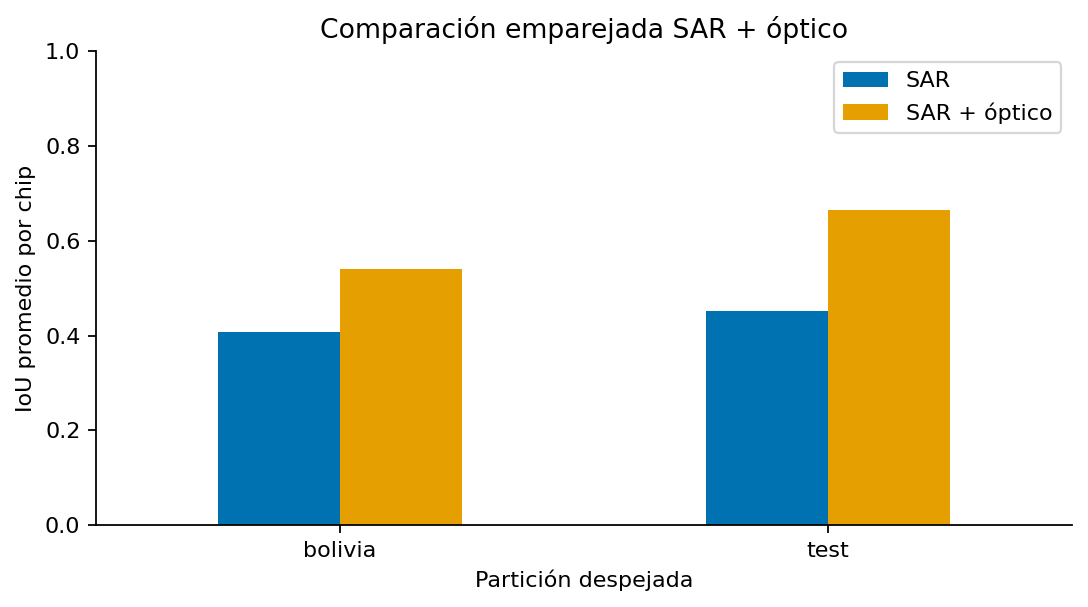

En **bolivia**, la diferencia de IoU de fusión frente a SAR es **+0.1332** (+13.32 puntos porcentuales). Este resultado corresponde a los chips despejados evaluados y a una única semilla; no demuestra superioridad estadística ni rendimiento bajo nubes.

En **test**, la diferencia de IoU de fusión frente a SAR es **+0.2140** (+21.40 puntos porcentuales). Este resultado corresponde a los chips despejados evaluados y a una única semilla; no demuestra superioridad estadística ni rendimiento bajo nubes.

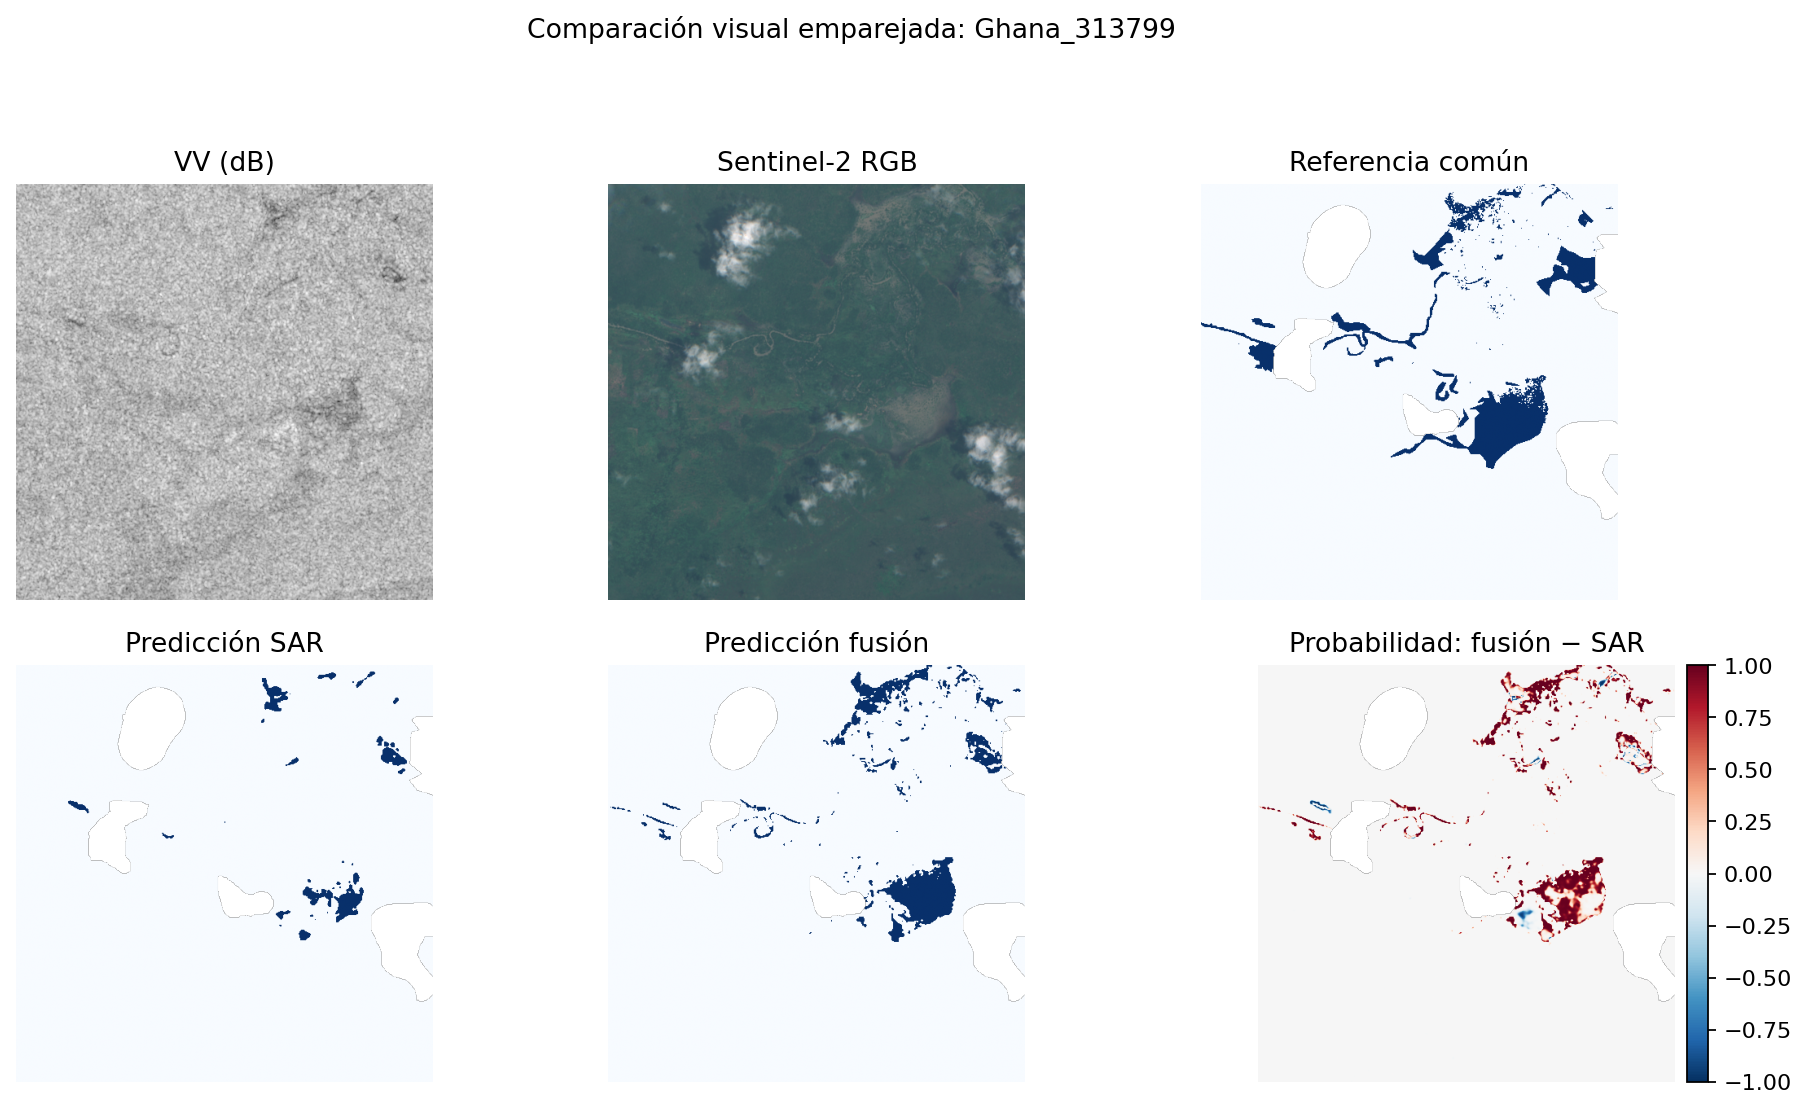

In [20]:
fusion_results=[]
if fusion_block is not None:
    display(Markdown(f'**Bloqueo del punto 6:** {fusion_block}. No se modificó el umbral de nubes ni se inventaron resultados.'))
else:
    display(pd.DataFrame([dict(particion=split,chips_despejados=len(entries)) for split,entries in clear_records.items()]))
    for name,channels in [('matched_sar',2),('matched_fusion',15)]:
        optical_stats=optical_normalization if channels==15 else None
        training=FloodDataset(limited(clear_records['train'],'train'),matched_sar_normalization,optical_stats,clear_masks,True)
        validation=FloodDataset(limited(clear_records['val'],'val'),matched_sar_normalization,optical_stats,clear_masks)
        complete=train_experiment(name,training,validation,channels,'combined')
        for split in ['test','bolivia']:
            dataset=FloodDataset(limited(clear_records[split],split),matched_sar_normalization,optical_stats,clear_masks)
            fusion_results.append(dict(**evaluate_experiment(name,dataset,channels,split),
                parameters=complete['parameters'],train_chips=complete['train_chips'],epochs=complete['epochs']))
    fusion_table=pd.DataFrame(fusion_results)
    fusion_table.to_csv(RUN_DIR/'fusion_metrics.csv',index=False)
    display(fusion_table.round(4))
    comparison=fusion_table.pivot(index='split',columns='experiment',values='mean_chip_iou')
    comparison['delta_fusion_menos_sar']=comparison.matched_fusion-comparison.matched_sar
    comparison.to_csv(RUN_DIR/'fusion_comparison.csv')
    display(comparison.round(4))
    fig,axis=plt.subplots(figsize=(7,4))
    comparison[['matched_sar','matched_fusion']].plot.bar(ax=axis,color=COLORS[:2],rot=0)
    axis.set(ylabel='IoU promedio por chip',xlabel='Partición despejada',ylim=(0,1),title='Comparación emparejada SAR + óptico')
    axis.legend(['SAR','SAR + óptico']);save_figure(fig,'06_fusion.png')
    for split,row in comparison.iterrows():
        delta=row['delta_fusion_menos_sar']
        display(Markdown(f'En **{split}**, la diferencia de IoU de fusión frente a SAR es **{delta:+.4f}** '
            f'({delta*100:+.2f} puntos porcentuales). Este resultado corresponde a los chips despejados evaluados y '
            'a una única semilla; no demuestra superioridad estadística ni rendimiento bajo nubes.'))
    example=limited(clear_records['test'],'test')[0]
    sar,truth,_=read_sar(example);optical,_=read_optical(example)
    valid=clear_masks[example['id']]
    rgb=np.clip(np.moveaxis(optical[[3,2,1]],0,-1)/0.3,0,1)
    probabilities=[]
    for name in ['matched_sar','matched_fusion']:
        with rasterio.open(RUN_DIR/'predictions'/name/'test'/f'{example["id"]}_probability.tif') as saved:
            probabilities.append(saved.read(1))
    fig,axes=plt.subplots(2,3,figsize=(12,7))
    arrays=[sar[0],rgb,np.ma.masked_where(~valid,truth),
            np.ma.masked_where(~valid,probabilities[0]>=0.5),
            np.ma.masked_where(~valid,probabilities[1]>=0.5),
            np.ma.masked_where(~valid,probabilities[1]-probabilities[0])]
    for axis,array,title,cmap in zip(axes.flat,arrays,
        ['VV (dB)','Sentinel-2 RGB','Referencia común','Predicción SAR','Predicción fusión','Probabilidad: fusión − SAR'],
        ['gray',None,'Blues','Blues','Blues','RdBu_r']):
        limits=({'vmin':-30,'vmax':0} if title=='VV (dB)' else
                ({'vmin':-1,'vmax':1} if cmap=='RdBu_r' else ({'vmin':0,'vmax':1} if cmap else {})))
        plotted=axis.imshow(array,cmap=cmap,**limits);axis.set_title(title);axis.axis('off')
        if cmap=='RdBu_r':
            fig.colorbar(plotted,ax=axis,fraction=0.04,pad=0.02)
    fig.suptitle(f'Comparación visual emparejada: {example["id"]}')
    save_figure(fig,'06_fusion_ejemplo.png')


In [21]:
all_names=[r['name'] for r in sar_training_results]+([] if fusion_block else ['matched_sar','matched_fusion'])
assert len(all_names)==(6 if fusion_block else 8)
completed=[read_json(RUN_DIR/'models'/name/'complete.json') for name in all_names]
assert all((RUN_DIR/'models'/name/'best.pt').is_file() for name in all_names)
assert all(row['epochs']>=1 and row['training_seconds']>0 for row in completed)
assert all(row['initialized_from_scratch'] and row['previous_checkpoints_loaded']==0 for row in completed)
if MODE=='full':
    assert all(row['scientific_run'] for row in completed)
receipt=dict(mode=MODE,models=all_names,models_completed=len(completed),acceptance_checks=len(test_results),
    fusion_block=fusion_block,manifest_identity=manifest['identity'],environment=environment,
    prediction_checks='Confusion counts recomputed from all exported GeoTIFF files',
    complete_utc=datetime.now(timezone.utc).isoformat(),new_training=True,resumed_verification=False,
    previous_generated_inputs_used=False, optical_network_required=False,
    cloud_masks_computed=read_json(RUN_DIR/'optical_protocol.json')['computed_masks'],
    rollback_boundary='Only this notebook and this execution output directory belong to the new solution.')
write_json(RUN_DIR/'execution_receipt.json',receipt)
write_json(RUN_DIR/'progress.json',dict(status='complete',mode=MODE,models=len(completed)))
display(Markdown(f'**Verificación terminada:** {len(completed)} modelos, {len(test_results)} comprobaciones aprobadas. '
    f'Modo: **{MODE}**. Las métricas se verificaron leyendo las predicciones persistidas.'))
display(pd.DataFrame(completed)[['name','channels','epochs','training_seconds','parameters']])


**Verificación terminada:** 8 modelos, 45 comprobaciones aprobadas. Modo: **full**. Las métricas se verificaron leyendo las predicciones persistidas.

,name,channels,epochs,training_seconds,parameters
0,gold_bce,2,50,232.449331,7762753
1,gold_dice,2,34,162.559581,7762753
2,gold_combined,2,50,234.023458,7762753
3,gold_weak_bce,2,35,2044.867301,7762753
4,gold_weak_dice,2,11,647.279459,7762753
5,gold_weak_combined,2,22,1265.718272,7762753
6,matched_sar,2,50,120.339270,7762753
7,matched_fusion,15,50,185.185855,7766497


**Fuentes y límites de interpretación**

- Enunciado del examen parcial, pregunta 2, páginas 3–5; condiciones generales, páginas 1 y 7.
- Ronneberger, Fischer y Brox. [U-Net: Convolutional Networks for Biomedical Image Segmentation](https://arxiv.org/abs/1505.04597), 2015. La arquitectura se implementa con módulos básicos de PyTorch.
- Bonafilia et al. [Sen1Floods11](https://openaccess.thecvf.com/content_CVPRW_2020/html/w11/Bonafilia_Sen1Floods11_A_Georeferenced_Dataset_to_Train_and_Test_Deep_Learning_CVPRW_2020_paper.html), CVPR Workshops 2020. [Repositorio y descripción de bandas](https://github.com/cloudtostreet/Sen1Floods11).
- Sentinel Hub. [s2cloudless: detector de nubes para Sentinel-2 L1C](https://github.com/sentinel-hub/sentinel2-cloud-detector). Se utiliza como preprocesamiento y se conserva su atribución; no sustituye una máscara de nubes validada localmente.
- [Documentación de PyTorch](https://docs.pytorch.org/docs/stable/) y [Rasterio](https://rasterio.readthedocs.io/en/stable/).

Este experimento segmenta agua anotada durante eventos de inundación; no distingue por sí solo agua permanente de agua recién inundada. Los mapas constituyen un resultado académico de detección de agua, no una validación operacional para respuesta de emergencia. Los modelos y parámetros se seleccionan con validación; los ejemplos de prueba se usan únicamente para evaluación y discusión de fallos.
